In [1]:
# Ciaran Whelan (23370211), Emma O'Reilly (23304472), Hersh Singh (23371137)
# Runs to the end without an error (checked 3 Nov 2026 using the saved runs, about 6 minutes on an RTX 3080)
# Reused: YOLOv8 neck, Detect head, loss and NMS from Ultralytics https://github.com/ultralytics/ultralytics, ImageNet ResNet-50 weights from torchvision https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html, mAP from torchmetrics https://lightning.ai/docs/torchmetrics/stable/detection/mean_average_precision.html

# Fire and Smoke Detection with a ResNet-50 and YOLOv8 Hybrid

CS4287 Assignment 1 (CNN). Sections follow the PDF report.

**Code.** The team's files from `src/`, `scripts/` and `notebooks/data_books/` are copied in under their paths, without the `from src` imports. Other changes are noted above the file.

**Reused code**
- Ultralytics YOLOv8 (https://github.com/ultralytics/ultralytics): `C2f`, `Conv`, `Detect`, `v8DetectionLoss`, `non_max_suppression`
- torchvision: ImageNet ResNet-50 weights, transforms, `box_convert`
- torchmetrics: `MeanAveragePrecision`

**Running.** Saved results in `results/` are loaded, so it runs in about 6 minutes. `ALLOW_TRAINING = True` trains anything missing, which takes hours on a GPU. Clone with the `data` and `results` submodules (`guide.md`), install `requirements.txt` and run from `notebooks/final/`.

## Setup

*Code: Hersh Singh*

In [2]:
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torchmetrics.detection import MeanAveragePrecision
from ultralytics.utils.nms import non_max_suppression

import json
import warnings
import subprocess
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats

import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

# same folders as src/config/paths.py, built from ROOT as a notebook has no __file__
DATASET_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
CSV_DIR = RESULTS_DIR / "csvs"
IMAGE_DIR = RESULTS_DIR / "images"
PLOT_DIR = RESULTS_DIR / "plots"
MODEL_DIR = RESULTS_DIR / "models"
WEIGHTS_DIR = MODEL_DIR / "weights"
SAVED_MODELS = RESULTS_DIR / "models" # MODEL_DIR is moved while saving runs, this stays put

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

# train_model logs CUDA memory but Mac doesnt support; ignore errors
if device.type != "cuda":
    torch.cuda.reset_peak_memory_stats = lambda: None
    torch.cuda.max_memory_allocated = lambda: 0

warnings.filterwarnings("ignore", message="CUDA is not available")
warnings.filterwarnings("ignore", message="Encountered more than 100 detections")

git_commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip()

# DataLoader workers are new processes that can't load classes defined in a notebook (ModelData), so load in this one
_dataloader_init = DataLoader.__init__
DataLoader.__init__ = lambda self, *args, **kwargs: _dataloader_init(self, *args, **(kwargs | {"num_workers": 0}))


def save_runs_to(folder):
    # Trainer.save_results writes to MODEL_DIR
    global MODEL_DIR
    MODEL_DIR = folder


print(device)

cuda


In [3]:
SEED = 42

# saved runs are always used; True also trains whatever is missing, which can take hours on a GPU
ALLOW_TRAINING = False

# cross-fold validation (section 3)
N_FOLDS = 5
MAX_DISTANCE = 4 # max differing bits for two images to be duplicates

CV_PARAMS = {
    "seed": SEED,
    "num_workers": 4 if device.type == "cuda" else 0, # 8 ran out of memory on Windows, each worker loads CUDA
    "pin_memory": device.type == "cuda",

    "batch_size": 8,
    "epochs": 8, # train.py uses 50, 8 for sake of time
    "accumulation_steps": 4,

    "learning_rate": 1e-3,
    "weight_decay": 1e-4,

    "model_name": "not saved",
}

# each setting's folds are saved in models/cross_validation/<name>/fold_<n>
CV_RUNS = {
    "base": {},
    "weight_decay_1e-3": {"weight_decay": 1e-3},
}

# sample of each fold so all 5 fit in about an hour on a GPU, None uses the whole fold
CV_TRAIN_IMAGES = 3000
CV_VAL_IMAGES = 1000

# hyperparameter tuning (section 5)
# settings of scripts/training/train.py and run 20261028_231315
BASE = {"learning_rate": 1e-3, "weight_decay": 1e-4, "backbone_lr_scale": 0.1, "augmentation": True}

# each changes one setting from BASE, {} is BASE as the reference
EXPERIMENTS = [
    {},
    {"learning_rate": 3e-4}, {"learning_rate": 1e-4},
    {"learning_rate": 2e-3}, {"learning_rate": 3e-3}, # 1e-3 was the highest rate tried on  Mac and still won
    {"weight_decay": 1e-5}, {"weight_decay": 1e-3},
    {"backbone_lr_scale": 1.0},
    {"augmentation": False},
]

BATCH_SIZE = 8
ACCUMULATION_STEPS = 4 # 32 images per step; same as train.py
EPOCHS = 8
TRAIN_IMAGES = 3000
VAL_IMAGES = 1000
VAL_FOLD = 0
NUM_WORKERS = 4 if device.type == "cuda" else 0

# final model (section 4)
FINAL_MODEL = "20261029_154330" # 50 epochs, random zoom-ins and flips, best validation mAP50-95

## 1. The Data Set

*Code: Ciaran Whelan. Report: Exploratory Data Analysis.*

`src/data/plots/utils.py`

In [4]:
def image_category(boxes):
    categories = {box["category"] for box in boxes}

    if categories == {0, 1}:
        return "both"
    elif categories == {1}:
        return "fire_only"
    elif categories == {0}:
        return "smoke_only"
    else:
        return "neither"

`src/data/plots/zero_boxes.py`

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

IMAGE_DIR = IMAGE_DIR / "data_analysis"

def plot_zero_boxes(zero_boxes, df):
    for idx in zero_boxes.index.unique():
        record = df.loc[idx]
        image_path = DATASET_DIR / record["path"]

        with Image.open(image_path) as img:
            image = img.copy()

        width, height = image.size

        fig, ax = plt.subplots(figsize=(10, 7))
        ax.imshow(image)

        for box in record["boxes"]:
            xc, yc, w, h = box["coordinates"]

            x = xc * width
            y = yc * height

            category = "Fire" if box["category"] == 1 else "Smoke"
            if w <= 0 or h <= 0:
                # White outline to make the marker visible
                ax.scatter(
                    x, y,
                    c="white",
                    marker="x",
                    s=350,
                    linewidths=6,
                    zorder=10,
                    clip_on=False
                )

                # Red X marking invalid annotation centre
                ax.scatter(
                    x, y,
                    c="red",
                    marker="x",
                    s=350,
                    linewidths=3,
                    zorder=11,
                    clip_on=False
                )

                ax.annotate(
                    category,
                    (x, y),
                    xytext=(12, -15),
                    textcoords="offset points",
                    color="white",
                    fontsize=11,
                    fontweight="bold",
                    bbox=dict(
                        facecolor="red",
                        edgecolor="white",
                        alpha=0.85,
                        pad=3
                    ),
                    zorder=12
                )

            else:
                rect = patches.Rectangle(
                    ((xc - w / 2) * width, (yc - h / 2) * height),
                    w * width,
                    h * height,
                    linewidth=2,
                    edgecolor="red" if category == "Fire" else "gray",
                    facecolor="none"
                )
                ax.add_patch(rect)

        ax.set_title(f"{image_path.name} | Index: {idx}")
        ax.set_xlim(-15, width + 15)
        ax.set_ylim(height + 15, -15)
        ax.axis("off")

        fig.savefig(IMAGE_DIR / f"error_box_{idx}.png", bbox_inches="tight")
        plt.close(fig)
    return list(IMAGE_DIR.glob("error_box_*.png"))

`notebooks/data_books/metadata.ipynb`

In [6]:
import pandas as pd
import json

from dataclasses import dataclass, field, asdict

from pathlib import Path

ROOT = Path.cwd().parents[1]

DATASET_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

CSV_DIR = RESULTS_DIR / "csvs" / "data"

In [7]:
CSV_DIR.mkdir(parents=True, exist_ok=True)
print(DATASET_DIR.exists())

True


In [8]:
@dataclass
class BoundingBox:
    category: int   #Fire-1, Smoke-0
    coordinates: tuple[float, float, float, float] #x_center, y_center, width, height

@dataclass
class LabelRecord:
    path: str
    split: str
    boxes: list[BoundingBox]
    label: int = field(init=False) # contains fire/smoke-1, doesnt-0

    def __post_init__(self):
        self.label = int(bool(self.boxes))

In [9]:
records: list[LabelRecord] = []
raw_records: list[LabelRecord] = []

invalid_count = 0
for split in DATASET_DIR.iterdir():
    if not split.is_dir():
        continue

    print(split.name)

    # Uses rglob as train has a lower level dir level so it recursively finds it
    for label_path in (split / "labels").rglob("*.txt"):
        boxes: list[BoundingBox] = []
        raw_boxes: list[BoundingBox] = []

        parts = list(label_path.parts)
        parts[parts.index("labels")] = "images"

        img_path = Path(*parts).with_suffix(".jpg")

        if not img_path.exists():
            print("[ERROR] Image does not exist in dir:", img_path)
            continue
        
        with open(label_path) as f:
            contents = f.read()

        if contents.strip():
            for lines in contents.splitlines():
                parts = lines.split()

                coordinates = tuple(float(x) for x in parts[1:])

                box = BoundingBox(
                        category=int(parts[0]),
                        coordinates=coordinates
                    )

                raw_boxes.append(box)

                xc, yc, w, h = coordinates

                # Discard zero or negative-area boxes
                if w <= 0 or h <= 0:
                    invalid_count += 1
                    continue

                # Convert to corner coordinates and clip
                x_min = max(0.0, xc - w / 2)
                x_max = min(1.0, xc + w / 2)

                y_min = max(0.0, yc - h / 2)
                y_max = min(1.0, yc + h / 2)

                # Discard boxes entirely outside the image
                if x_min >= x_max or y_min >= y_max:
                    invalid_count += 1
                    continue

                # Convert back to YOLO format
                boxes.append(
                    BoundingBox(
                        category=box.category,
                        coordinates=(
                            (x_min + x_max) / 2,
                            (y_min + y_max) / 2,
                            x_max - x_min,
                            y_max - y_min
                        )
                    )
                )     

        records.append(
            LabelRecord(
                path=img_path.relative_to(DATASET_DIR).as_posix(),
                split=split.name,
                boxes=boxes
            )
        )

        raw_records.append(
            LabelRecord(
                path=img_path.relative_to(DATASET_DIR).as_posix(),
                split=split.name,
                boxes=raw_boxes
            )
        )

test
train
val


In [10]:
invalid_count

18

In [11]:
raw_df = pd.DataFrame([asdict(record) for record in raw_records])
df = pd.DataFrame([asdict(record) for record in records])

df

,path,split,boxes,label
0,test/images/AoF06723.jpg,test,[],0
1,test/images/AoF06724.jpg,test,[],0
2,test/images/AoF06725.jpg,test,[],0
3,test/images/AoF06726.jpg,test,[],0
4,test/images/AoF06727.jpg,test,[],0
...,...,...,...,...
21522,val/images/WEB09432.jpg,val,"[{'category': 0, 'coordinates': (0.47777777777...",1
21523,val/images/WEB09433.jpg,val,"[{'category': 0, 'coordinates': (0.48245614035...",1
21524,val/images/WEB09436.jpg,val,"[{'category': 1, 'coordinates': (0.41956018518...",1
21525,val/images/WEB09440.jpg,val,"[{'category': 0, 'coordinates': (0.41333333333...",1


In [12]:
# Serialize bounding-box data to JSON strings for CSV storage
raw_df["boxes"] = raw_df["boxes"].apply(json.dumps)
df["boxes"] = df["boxes"].apply(json.dumps)

raw_df.to_csv(CSV_DIR / "metadata_raw.csv", index=False)
df.to_csv(CSV_DIR / "metadata.csv", index=False)

print(f"Processed {len(df)} images")

Processed 21527 images


`notebooks/data_books/01_data_distribution.ipynb`

In [13]:
import json
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

# src/config/paths.py
DATASET_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

CSV_DIR = RESULTS_DIR / "csvs"
IMAGE_DIR = RESULTS_DIR / "images" 
PLOT_DIR = RESULTS_DIR / "plots" 
MODEL_DIR = RESULTS_DIR / "models"
WEIGHTS_DIR = MODEL_DIR / "weights"

ANALYSIS_DIR = CSV_DIR / "data_analysis"
IMAGE_DIR = IMAGE_DIR / "data_analysis"
PLOT_DIR = PLOT_DIR / "data_analysis"

In [14]:
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [15]:
df = pd.read_csv(CSV_DIR/"data/metadata.csv")

df["boxes"] = df["boxes"].apply(json.loads)

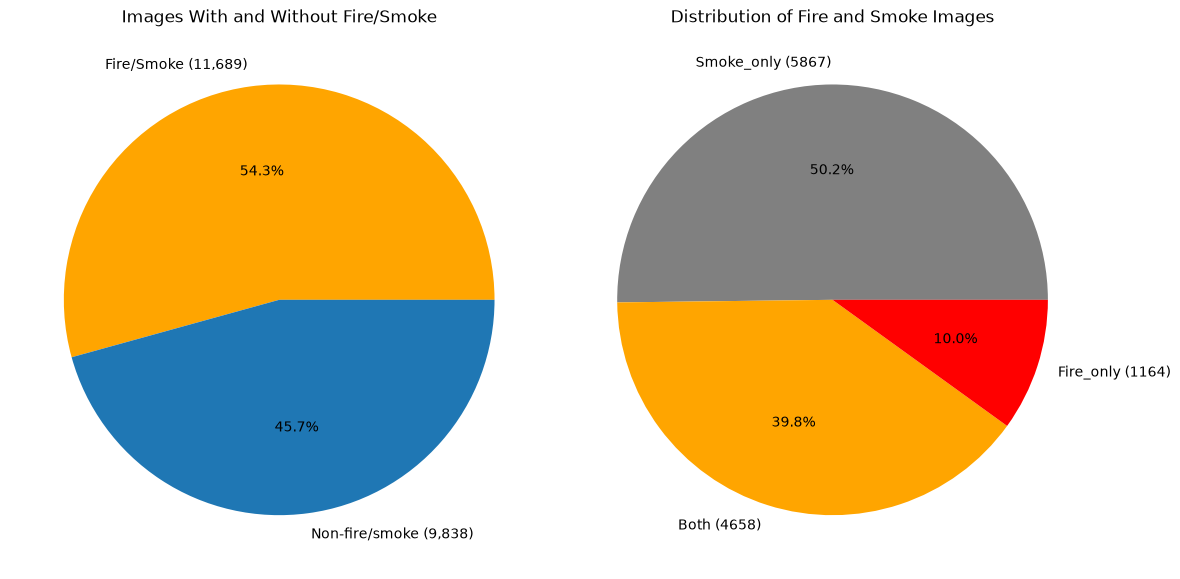

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12,6))

fire_split = df["label"].map({0: "Non-fire/smoke", 1: "Fire/Smoke"}).value_counts() # counts for fire/smoke(1), non-smoke/fire(0)
labels = [f"{label} ({count:,})" for label, count in fire_split.items()]

fire_split.plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=labels,
    colors=["orange", "tab:blue"],
    ax=axes[0]
)
axes[0].set_title("Images With and Without Fire/Smoke")

df["category"] = df["boxes"].apply(image_category) # gets image category based on boxes in the image
cat_counts = df.loc[
    df["category"] != "neither", # Exclude neither because its already shown in fire/non-fire
    "category"
].value_counts()
labels = [f"{label.capitalize()} ({count})" for label, count in cat_counts.items()]

cat_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=labels,
    colors=["grey", "orange", "red"],
    ax=axes[1]
)
axes[1].set_title("Distribution of Fire and Smoke Images")

plt.tight_layout()
fig.savefig(PLOT_DIR / "image_category_distribution.svg")
plt.show()

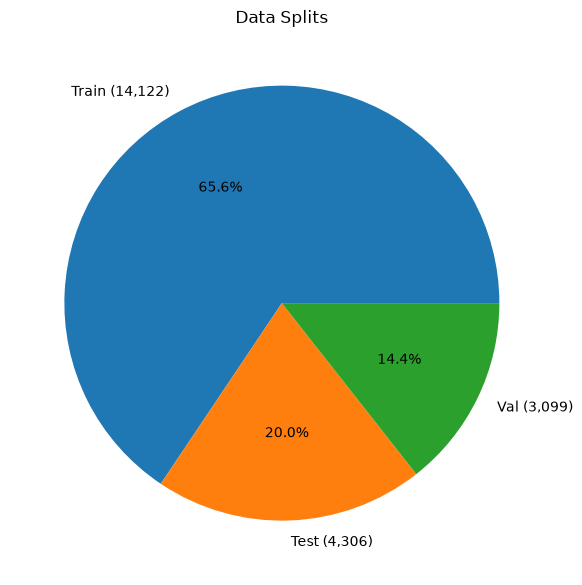

In [17]:
plt.figure(figsize=(6, 6))

split_counts = df["split"].value_counts()
labels = [f"{label.capitalize()} ({count:,})" for label, count in split_counts.items()]

split_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=labels,
)
plt.title("Data Splits")
plt.tight_layout()
plt.savefig(PLOT_DIR / "data_split.svg")
plt.show()

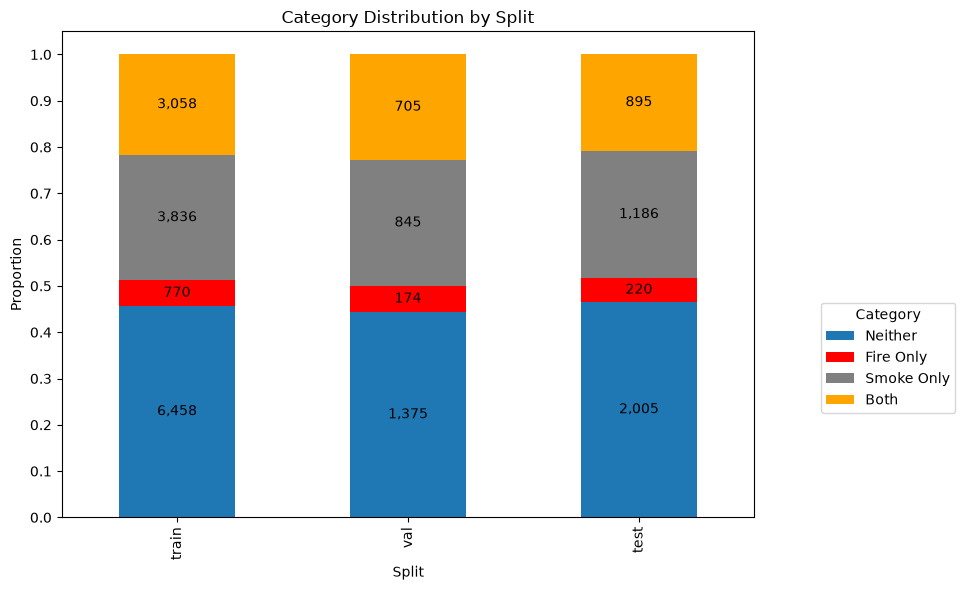

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))

# Ensures consitent category and split ordering
order = ["neither", "fire_only", "smoke_only", "both"]
splits = ["train", "val", "test"]

ax = (df.groupby("split")["category"].value_counts(normalize=True).unstack()
      .reindex(columns=order, fill_value=0)
      .reindex(splits)
      .plot(
          kind="bar", 
          stacked=True,
          color=["tab:blue", "red", "grey", "orange"],
          ax=ax
        )
      )

ax.legend(title="Category", labels=["Neither", "Fire Only", "Smoke Only", "Both"], bbox_to_anchor=(1.3, 0.2), loc="lower right")

split_sizes = df.groupby("split").size().reindex(splits)

# Goes through the boxes in the axis and gives them their counts
for c in ax.containers:
    labels = [
        f"{round(v.get_height() * split_sizes.iloc[i]):,}"
        if v.get_height() > 0 else ""
        for i, v in enumerate(c)
    ]

    ax.bar_label(c, labels=labels, label_type="center")

plt.title("Category Distribution by Split")

plt.xlabel("Split")
plt.ylabel("Proportion")
plt.yticks(np.arange(0, 1.1, 0.1))

plt.tight_layout()
plt.savefig(PLOT_DIR / "category_distribution_by_split.svg")
plt.show()

In [19]:
sizes_df = df["boxes"].explode().dropna().apply(pd.Series)

sizes_df[["xc", "yc", "width", "height"]] = pd.DataFrame(
    sizes_df["coordinates"].tolist(),
    index=sizes_df.index
)

sizes_df["path"] = df.loc[sizes_df.index, "path"].to_numpy()
sizes_df["area"] = sizes_df["width"] * sizes_df["height"]
sizes_df["split"] = df.loc[sizes_df.index, "split"].to_numpy()

# box sizes df is created here for labels and is then used later
sizes_df.to_csv(ANALYSIS_DIR / "box_sizes.csv", index=False)
sizes_df

,category,coordinates,xc,yc,width,height,path,area,split
255,0,"[0.951171875, 0.18541666666666667, 0.057031250...",0.951172,0.185417,0.057031,0.093056,test/images/AoF06978.jpg,0.005307,test
895,0,"[0.33242187500000003, 0.40208333333333335, 0.0...",0.332422,0.402083,0.028906,0.031944,test/images/AoF07618.jpg,0.000923,test
950,0,"[0.35781250000000003, 0.3590277777777778, 0.04...",0.357813,0.359028,0.040625,0.040278,test/images/AoF07673.jpg,0.001636,test
995,1,"[0.743359375, 0.6493055555555556, 0.1304687499...",0.743359,0.649306,0.130469,0.112500,test/images/AoF07718.jpg,0.014678,test
995,1,"[0.46132812500000003, 0.6104166666666667, 0.04...",0.461328,0.610417,0.047656,0.098611,test/images/AoF07718.jpg,0.004699,test
...,...,...,...,...,...,...,...,...,...
21524,0,"[0.46990740740740733, 0.39254766031195837, 0.1...",0.469907,0.392548,0.194444,0.185442,val/images/WEB09436.jpg,0.036058,val
21525,0,"[0.41333333333333333, 0.29880952380952386, 0.5...",0.413333,0.298810,0.565333,0.526190,val/images/WEB09440.jpg,0.297473,val
21525,0,"[0.056666666666666664, 0.43809523809523815, 0....",0.056667,0.438095,0.100000,0.133333,val/images/WEB09440.jpg,0.013333,val
21526,0,"[0.5949579831932773, 0.43297587131367293, 0.79...",0.594958,0.432976,0.796639,0.833780,val/images/WEB09442.jpg,0.664222,val


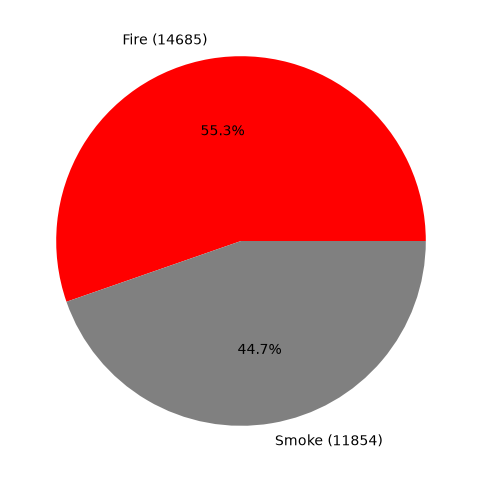

In [20]:
label_counts = sizes_df["category"].value_counts()

fire_count = label_counts.get(1, 0)
smoke_count = label_counts.get(0, 0)

labels = [f"Fire ({fire_count})", f"Smoke ({smoke_count})"]

plt.figure(figsize=(6, 6))

plt.pie(
    [fire_count, smoke_count],
    autopct="%1.1f%%",
    labels=labels,
    colors=["red", "grey"]
)

plt.savefig(PLOT_DIR / "label_distribution.svg")
plt.show()

`notebooks/data_books/02_bounding_boxes.ipynb`

Changed: IPython's `Image` is imported as `DisplayImage` so it doesn't replace PIL's `Image`.

In [21]:
import json
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, Image as DisplayImage, clear_output

import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

# src/config/paths.py
DATASET_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

CSV_DIR = RESULTS_DIR / "csvs"
IMAGE_DIR = RESULTS_DIR / "images" 
PLOT_DIR = RESULTS_DIR / "plots" 
MODEL_DIR = RESULTS_DIR / "models"
WEIGHTS_DIR = MODEL_DIR / "weights"

ANALYSIS_DIR = CSV_DIR / "data_analysis"
IMAGE_DIR = IMAGE_DIR / "data_analysis"
PLOT_DIR = PLOT_DIR / "data_analysis"

In [22]:
raw_df = pd.read_csv(CSV_DIR/"data/metadata_raw.csv")

raw_df["boxes"] = raw_df["boxes"].apply(json.loads)

In [23]:
raw_sizes = raw_df["boxes"].explode().dropna().apply(pd.Series)

raw_sizes[["xc", "yc", "width", "height"]] = pd.DataFrame(
    raw_sizes["coordinates"].tolist(),
    index=raw_sizes.index
)

raw_sizes["path"] = raw_df.loc[raw_sizes.index, "path"].to_numpy()
raw_sizes["area"] = raw_sizes["width"] * raw_sizes["height"]
raw_sizes["split"] = raw_df.loc[raw_sizes.index, "split"].to_numpy()

raw_sizes

,category,coordinates,xc,yc,width,height,path,area,split
255,0,"[0.951171875, 0.18541666666666667, 0.057031250...",0.951172,0.185417,0.057031,0.093056,test/images/AoF06978.jpg,0.005307,test
895,0,"[0.33242187500000003, 0.40208333333333335, 0.0...",0.332422,0.402083,0.028906,0.031944,test/images/AoF07618.jpg,0.000923,test
950,0,"[0.35781250000000003, 0.3590277777777778, 0.04...",0.357813,0.359028,0.040625,0.040278,test/images/AoF07673.jpg,0.001636,test
995,1,"[0.743359375, 0.6493055555555556, 0.13046875, ...",0.743359,0.649306,0.130469,0.112500,test/images/AoF07718.jpg,0.014678,test
995,1,"[0.46132812500000003, 0.6104166666666667, 0.04...",0.461328,0.610417,0.047656,0.098611,test/images/AoF07718.jpg,0.004699,test
...,...,...,...,...,...,...,...,...,...
21524,0,"[0.4699074074074074, 0.39254766031195837, 0.19...",0.469907,0.392548,0.194444,0.185442,val/images/WEB09436.jpg,0.036058,val
21525,0,"[0.41333333333333333, 0.29880952380952386, 0.5...",0.413333,0.298810,0.565333,0.526190,val/images/WEB09440.jpg,0.297473,val
21525,0,"[0.056666666666666664, 0.43809523809523815, 0....",0.056667,0.438095,0.100000,0.133333,val/images/WEB09440.jpg,0.013333,val
21526,0,"[0.5949579831932773, 0.43297587131367293, 0.79...",0.594958,0.432976,0.796639,0.833780,val/images/WEB09442.jpg,0.664222,val


In [24]:
zero_boxes = raw_sizes[raw_sizes["area"] == 0]

print("Zero-area boxes:", len(zero_boxes))

Zero-area boxes: 18


In [25]:
x_min = (raw_sizes["xc"] - raw_sizes["width"] / 2) < 0
x_max = (raw_sizes["xc"] + raw_sizes["width"] / 2) > 1

y_min = (raw_sizes["yc"] - raw_sizes["height"] / 2) < 0
y_max = (raw_sizes["yc"] + raw_sizes["height"] / 2) > 1

out_of_bounds = x_min | x_max | y_min | y_max

print("Total out-of-bounds boxes:", out_of_bounds.sum())
print("Percentage:", f"{out_of_bounds.mean() * 100:.2f}%")
print("Affected images:", raw_sizes.loc[out_of_bounds, "path"].nunique())

Total out-of-bounds boxes: 379
Percentage: 1.43%
Affected images: 322


In [26]:
bounds = pd.DataFrame({
    "left": raw_sizes["xc"] - raw_sizes["width"] / 2,
    "right": raw_sizes["xc"] + raw_sizes["width"] / 2,
    "top": raw_sizes["yc"] - raw_sizes["height"] / 2,
    "bottom": raw_sizes["yc"] + raw_sizes["height"] / 2
})

# Treats values as > 0 only clips when < 0
# For example [-0.15, 0.8, 0.1, -0.2] -> [0.15, 0, 0, 0.2]
violations = pd.DataFrame({
    "left": (-bounds["left"]).clip(lower=0),
    "right": (bounds["right"] - 1).clip(lower=0),
    "top": (-bounds["top"]).clip(lower=0),
    "bottom": (bounds["bottom"] - 1).clip(lower=0)
})

raw_sizes["boundary_excess"] = violations.max(axis=1)
raw_sizes.loc[out_of_bounds, "boundary_excess"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
)

count    379.000000
mean       0.008162
std        0.011699
min        0.000756
50%        0.003750
90%        0.017188
95%        0.030556
99%        0.054271
max        0.094059
Name: boundary_excess, dtype: float64

In [27]:
image_paths = plot_zero_boxes(zero_boxes, raw_df)
current = 0

prev_btn = widgets.Button(description="Previous")
next_btn = widgets.Button(description="Next")
output = widgets.Output()

def show_image():
    with output:
        clear_output(wait=True)
        display(DisplayImage(filename=str(image_paths[current])))

    prev_btn.disabled = current == 0
    next_btn.disabled = current == len(image_paths) - 1

def navigate(change):
    global current

    if change == next_btn:
        current += 1
    else:
        current -= 1

    show_image()

prev_btn.on_click(navigate)
next_btn.on_click(navigate)

display(widgets.HBox([prev_btn, next_btn]), output)
show_image()

Output()

In [28]:
sizes_df = pd.read_csv(ANALYSIS_DIR/"box_sizes.csv")

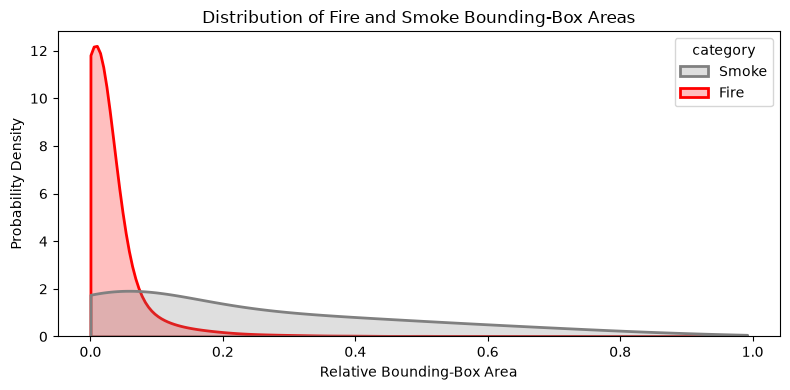

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))

plot_df = sizes_df.copy()
plot_df["category"] = plot_df["category"].map({
    0: "Smoke",
    1: "Fire"
})

sns.kdeplot(
    data=plot_df,
    x="area",
    hue="category",
    hue_order=["Smoke", "Fire"],
    palette={"Smoke": "grey", "Fire": "red"},
    common_norm=False,
    fill=True,
    alpha=0.25,
    linewidth=2,
    cut=0,
    bw_adjust=3, # Makes the curve smoother
    ax=ax
)

ax.set_title("Distribution of Fire and Smoke Bounding-Box Areas")
ax.set_xlabel("Relative Bounding-Box Area")
ax.set_ylabel("Probability Density")

fig.tight_layout()
fig.savefig(PLOT_DIR / "fire_vs_smoke_area_distribution.svg")
plt.show()

Probability density represents how concentrated bounding-box areas are within a particular range, where the probability of an annotation falling within that range is represented by the area under the curve.

For example:
Relative bounding box-area: 0.05
Probability Density: 12

Probability = 12 x 0.05 = 0.06 => 6%

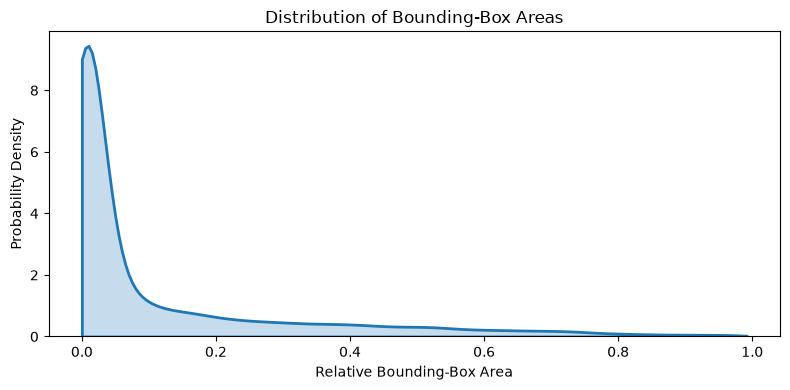

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.kdeplot(
    data=sizes_df,
    x="area",
    color="tab:blue",
    fill=True,
    alpha=0.25,
    linewidth=2,
    cut=0,
    ax=ax
)

ax.set_title("Distribution of Bounding-Box Areas")
ax.set_xlabel("Relative Bounding-Box Area")
ax.set_ylabel("Probability Density")

fig.tight_layout()
fig.savefig(PLOT_DIR / "box_area_distribution.svg")
plt.show()

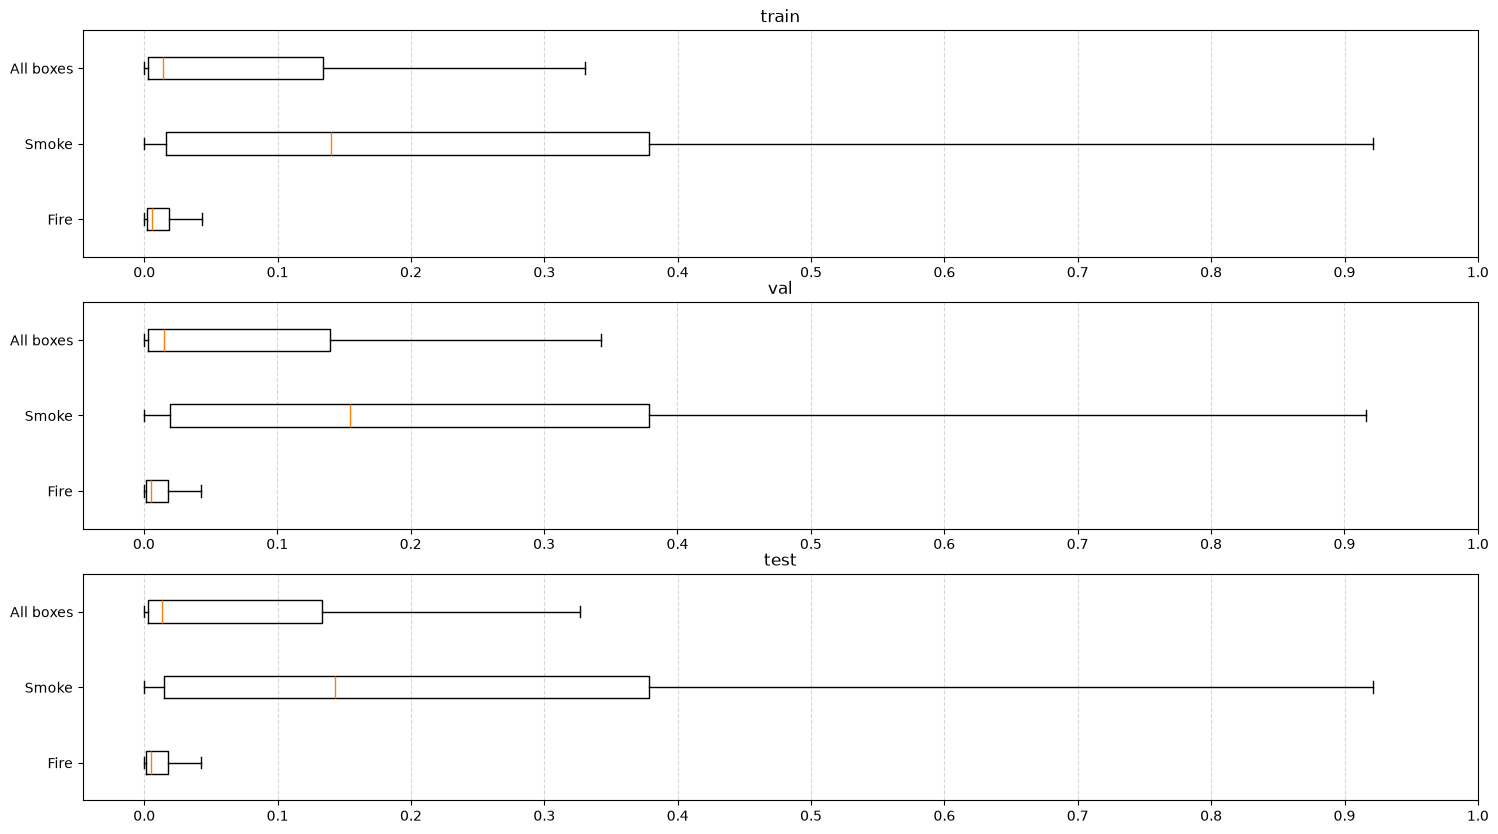

In [31]:
fig, axes = plt.subplots(3, 1, figsize=(18, 10))

for ax, split in zip(axes, ["train", "val", "test"]):
    ax.boxplot(
        [
            sizes_df["area"][(sizes_df["split"] == split) & (sizes_df["category"] == 1)],
            sizes_df["area"][(sizes_df["split"] == split) & (sizes_df["category"] == 0)],
            sizes_df["area"][sizes_df["split"] == split],
        ],
        orientation="horizontal",
        tick_labels=["Fire", "Smoke", "All boxes"],
        showfliers=False
    )
    ax.set_xticks(np.arange(0, 1.1, 0.1))
    ax.grid(axis="x", linestyle="--", alpha=0.5)
    ax.set_title(split)

plt.savefig(PLOT_DIR / "area_dist_by_split.svg")
plt.show()

`notebooks/data_books/03_image_properties.ipynb`

In [32]:
import json
import pandas as pd
import numpy as np

import cv2 
from typing import TypedDict

import matplotlib.pyplot as plt
import seaborn as sns

import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

# src/config/paths.py
DATASET_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

CSV_DIR = RESULTS_DIR / "csvs"
IMAGE_DIR = RESULTS_DIR / "images" 
PLOT_DIR = RESULTS_DIR / "plots" 
MODEL_DIR = RESULTS_DIR / "models"
WEIGHTS_DIR = MODEL_DIR / "weights"

ANALYSIS_DIR = CSV_DIR / "data_analysis"
IMAGE_DIR = IMAGE_DIR / "data_analysis"
PLOT_DIR = PLOT_DIR / "data_analysis"

STATS_DIR = ANALYSIS_DIR / "image_properties"

In [33]:
STATS_DIR.mkdir(parents=True, exist_ok=True)

In [34]:
df = pd.read_csv(CSV_DIR / "data/metadata.csv")
df["boxes"] = df["boxes"].apply(json.loads)

In [35]:
class ImageProperties(TypedDict):
    path: str
    split: str
    image_category: str
    
    width: int
    height: int
    area: int

    coverage : float
    
    brightness: float
    sharpness: float
    contrast: float

In [36]:
def create_masks(boxes, width, height):
    masks = {
        "all": np.zeros((height, width), dtype=bool),
        "smoke": np.zeros((height, width), dtype=bool),
        "fire": np.zeros((height, width), dtype=bool)
    }

    for box in boxes:
        xc, yc, w, h = box["coordinates"]

        # coordinates are already cleaned
        x1 = int(np.floor((xc - w / 2) * width))
        y1 = int(np.floor((yc - h / 2) * height))
        x2 = int(np.ceil((xc + w / 2) * width))
        y2 = int(np.ceil(yc + h / 2) * height)

        assert 0 <= x1 < x2 <= width
        assert 0 <= y1 < y2 <= height

        category = "smoke" if box["category"] == 0 else "fire"

        masks[category][y1:y2, x1:x2] = True
        masks["all"][y1:y2, x1:x2] = True
    return masks

In [37]:
df["category"] = df["boxes"].apply(image_category)

REGIONS = ["global", "background", "all", "fire", "smoke"]
PROPS = ["brightness", "contrast", "sharpness"]

In [38]:
stats = {}

# background is exluded for now as theres a couple calculations in verifying that
expected = {
    "global": len(df),
    "all": df["boxes"].apply(bool).sum(),
    "fire": df["boxes"].apply(
        lambda boxes: any(box["category"] == 1 for box in boxes)
    ).sum(),
    "smoke": df["boxes"].apply(
        lambda boxes: any(box["category"] == 0 for box in boxes)
    ).sum()
}

valid = True

for region in REGIONS:
    path = STATS_DIR / f"{region}.csv"

    if not path.exists():
        print(f"Path for {region} does not exist")
        valid = False
        break

    stats[region] = pd.read_csv(path)

    # background is excluded for now as each image needs to be processed beforehand to see if the background is valid
    if region == "background":
        continue

    if len(stats[region]) != expected[region]:
        print(f"Unexpected length for {region}")
        valid = False
        break

# if every other region type was valid create background regions
if valid:
    fully_covered = set(
        stats["all"].loc[
            stats["all"]["coverage"] >= 1.0, "path"
        ]
    )

    expected_background = set(df["path"]) - fully_covered

    background = stats["background"]

    if (
        len(background) != len(expected_background)
        or set(background["path"]) != expected_background
    ):
        print("Unexpected background records")
        valid = False
        
if not valid:
    stats = {region: [] for region in REGIONS}

    for row in df.itertuples():
        img = cv2.imread(str(DATASET_DIR / row.path))

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        laplacian = cv2.Laplacian(gray, cv2.CV_64F)

        h, w = gray.shape
        
        masks = create_masks(row.boxes, w, h)

        masks["global"] = np.ones((h, w), dtype=bool)
        masks["background"] = ~masks["all"]

        for region, mask in masks.items():
            if not mask.any():
                continue

            properties = ImageProperties(
                path=row.path,
                split=row.split,
                image_category=row.category,

                width=w,
                height=h,
                area=w * h,

                coverage=mask.mean(),

                brightness=gray[mask].mean(),
                sharpness=laplacian[mask].var(),
                contrast=gray[mask].std(),
            )

            stats[region].append(properties)

    for region in REGIONS:
        stats[region] = pd.DataFrame(stats[region])
        stats[region].to_csv(STATS_DIR / f"{region}.csv", index=False)

stats["global"]

,path,split,image_category,width,height,area,coverage,brightness,sharpness,contrast
0,test/images/AoF07886.jpg,test,fire_only,1280,720,921600,1.0,3.754117,736.376030,18.141169
1,test/images/WEB11522.jpg,test,both,640,360,230400,1.0,42.789961,88.260868,59.770824
2,test/images/WEB09787.jpg,test,neither,640,360,230400,1.0,105.551267,229.945659,65.509887
3,test/images/WEB09818.jpg,test,neither,640,360,230400,1.0,96.777999,846.224447,56.515483
4,test/images/WEB11601.jpg,test,both,640,360,230400,1.0,119.879401,239.031656,51.075224
...,...,...,...,...,...,...,...,...,...,...
21522,train/images/chunk_001/WEB01662.jpg,train,neither,640,360,230400,1.0,131.233880,163.511475,81.138431
21523,train/images/chunk_001/WEB04100.jpg,train,both,900,618,556200,1.0,124.073445,211.992874,74.352174
21524,train/images/chunk_001/WEB02368.jpg,train,neither,1280,720,921600,1.0,174.162492,932.555573,47.020802
21525,train/images/chunk_001/WEB03497.jpg,train,neither,1116,735,820260,1.0,101.521403,225.712010,52.048592


In [39]:
stats["all"]

,path,split,image_category,width,height,area,coverage,brightness,sharpness,contrast
0,test/images/AoF07886.jpg,test,fire_only,1280,720,921600,0.024309,10.623622,137.020888,39.914979
1,test/images/WEB11522.jpg,test,both,640,360,230400,0.918537,45.133359,95.642715,61.190064
2,test/images/WEB11601.jpg,test,both,640,360,230400,0.869006,118.418337,236.538004,47.502620
3,test/images/AoF08001.jpg,test,smoke_only,1280,720,921600,0.034089,85.147791,176.111997,49.814720
4,test/images/AoF08003.jpg,test,smoke_only,1280,720,921600,0.052572,86.993416,2413.765110,63.188348
...,...,...,...,...,...,...,...,...,...,...
11684,train/images/chunk_001/AoF06148.jpg,train,smoke_only,1280,720,921600,0.045655,109.116741,1831.301130,44.795940
11685,train/images/chunk_001/PublicDataset00235.jpg,train,smoke_only,480,360,172800,0.599844,81.939953,169.311063,46.978995
11686,train/images/chunk_001/AoF06439.jpg,train,smoke_only,1280,720,921600,0.033418,67.460322,1101.000528,49.111314
11687,train/images/chunk_001/WEB04100.jpg,train,both,900,618,556200,0.681143,121.112545,285.280610,78.043328


In [40]:
stats["fire"]

,path,split,image_category,width,height,area,coverage,brightness,sharpness,contrast
0,test/images/AoF07886.jpg,test,fire_only,1280,720,921600,0.024309,10.623622,137.020888,39.914979
1,test/images/WEB11522.jpg,test,both,640,360,230400,0.104049,66.649898,160.994566,88.937590
2,test/images/WEB11601.jpg,test,both,640,360,230400,0.361888,102.841555,306.388211,35.244541
3,test/images/WEB11096.jpg,test,both,700,466,326200,0.033550,88.100694,255.082111,36.011515
4,test/images/WEB11445.jpg,test,both,1000,562,562000,0.003299,122.420712,1022.814743,40.925155
...,...,...,...,...,...,...,...,...,...,...
5817,train/images/chunk_001/PublicDataset00033.jpg,train,fire_only,540,360,194400,0.020525,6.902757,405.815496,26.278517
5818,train/images/chunk_001/WEB03896.jpg,train,both,1280,720,921600,0.070736,131.695981,9.954733,59.982098
5819,train/images/chunk_001/WEB03837.jpg,train,fire_only,640,352,225280,0.166806,36.168317,882.345566,73.724557
5820,train/images/chunk_001/WEB03946.jpg,train,both,848,480,407040,0.092573,95.207930,461.403099,28.637596


In [41]:
comparisons = {}

for region in ("all", "fire", "smoke"):

    # Joins images with the properties of images one -> one
    comparison = stats[region][
        ["path", "split", "image_category", "coverage", *PROPS]
    ].merge(
        stats["background"][["path", *PROPS]],
        on="path",
        suffixes=(f"_{region}", "_background"),
        validate="one_to_one"
    )

    for prop in PROPS:
        comparison[f"{prop}_delta"] = (
            comparison[f"{prop}_{region}"]
            - comparison[f"{prop}_background"]
        )

        comparison[f"{prop}_abs_delta"] = comparison[f"{prop}_delta"].abs()

    comparisons[region] = comparison
    comparison.to_csv(STATS_DIR / f"{region}_compare_background.csv", index=False)

In [42]:
comparisons["smoke"]

,path,split,image_category,coverage,brightness_smoke,contrast_smoke,sharpness_smoke,brightness_background,contrast_background,sharpness_background,brightness_delta,brightness_abs_delta,contrast_delta,contrast_abs_delta,sharpness_delta,sharpness_abs_delta
0,test/images/WEB11522.jpg,test,both,0.918537,45.133359,61.190064,95.642715,16.366828,29.609866,5.025959,28.766531,28.766531,31.580198,31.580198,90.616756,90.616756
1,test/images/WEB11601.jpg,test,both,0.869006,118.418337,47.502620,236.538004,129.572016,69.547893,255.573939,-11.153679,11.153679,-22.045274,22.045274,-19.035935,19.035935
2,test/images/AoF08001.jpg,test,smoke_only,0.034089,85.147791,49.814720,176.111997,110.038811,75.492796,979.347687,-24.891020,24.891020,-25.678076,25.678076,-803.235690,803.235690
3,test/images/AoF08003.jpg,test,smoke_only,0.052572,86.993416,63.188348,2413.765110,101.606068,64.548103,1008.155738,-14.612652,14.612652,-1.359754,1.359754,1405.609371,1405.609371
4,test/images/AoF08247.jpg,test,smoke_only,0.064098,110.696782,44.314624,1976.304795,111.220073,61.415118,2069.408098,-0.523291,0.523291,-17.100494,17.100494,-93.103303,93.103303
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10511,train/images/chunk_001/AoF06148.jpg,train,smoke_only,0.045655,109.116741,44.795940,1831.301130,110.157516,61.209378,1966.783232,-1.040775,1.040775,-16.413438,16.413438,-135.482102,135.482102
10512,train/images/chunk_001/PublicDataset00235.jpg,train,smoke_only,0.599844,81.939953,46.978995,169.311063,85.180008,38.319579,174.596087,-3.240054,3.240054,8.659416,8.659416,-5.285024,5.285024
10513,train/images/chunk_001/AoF06439.jpg,train,smoke_only,0.033418,67.460322,49.111314,1101.000528,97.142881,70.810043,1699.109618,-29.682559,29.682559,-21.698729,21.698729,-598.109090,598.109090
10514,train/images/chunk_001/WEB04100.jpg,train,both,0.681143,121.112545,78.043328,285.280610,130.398538,65.328879,55.435026,-9.285993,9.285993,12.714449,12.714449,229.845584,229.845584


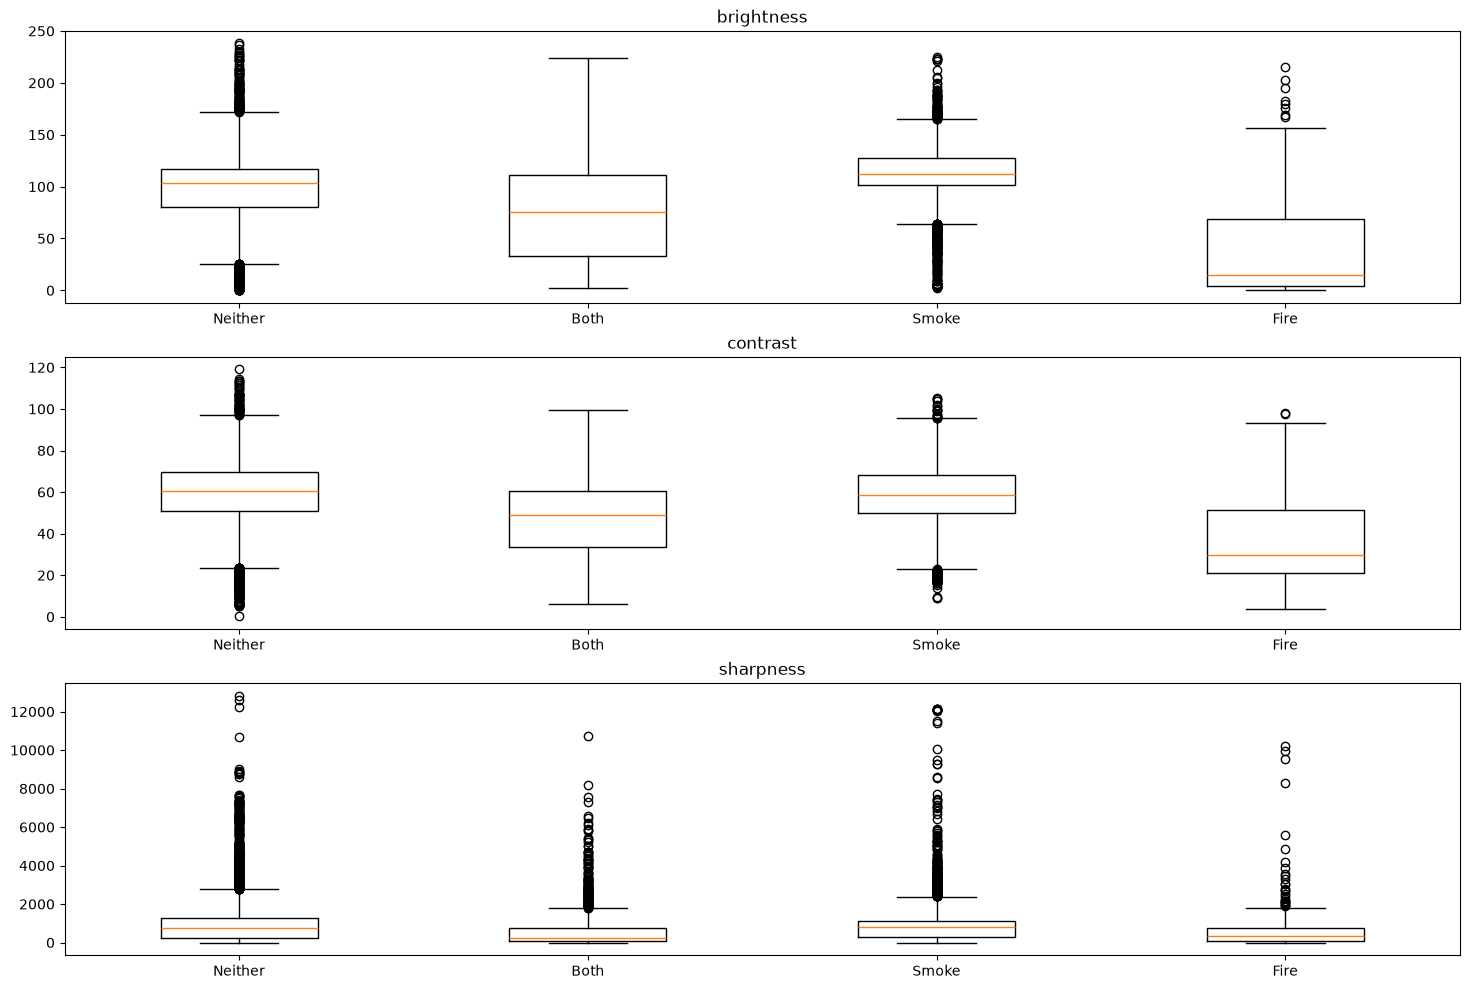

In [43]:
fig, axes = plt.subplots(3, 1, figsize=(18, 12))

for ax, prop in zip(axes, ["brightness", "contrast", "sharpness"]):
    ax.boxplot(
        [
            stats["global"][prop][stats["global"]["image_category"] == "neither"],
            stats["global"][prop][stats["global"]["image_category"] == "both"],
            stats["global"][prop][stats["global"]["image_category"] == "smoke_only"],
            stats["global"][prop][stats["global"]["image_category"] == "fire_only"],
        ],
        tick_labels=["Neither", "Both", "Smoke", "Fire"]
    )
    ax.set_title(prop)

plt.savefig(PLOT_DIR / "image_prop_box_plots.svg")
plt.show()

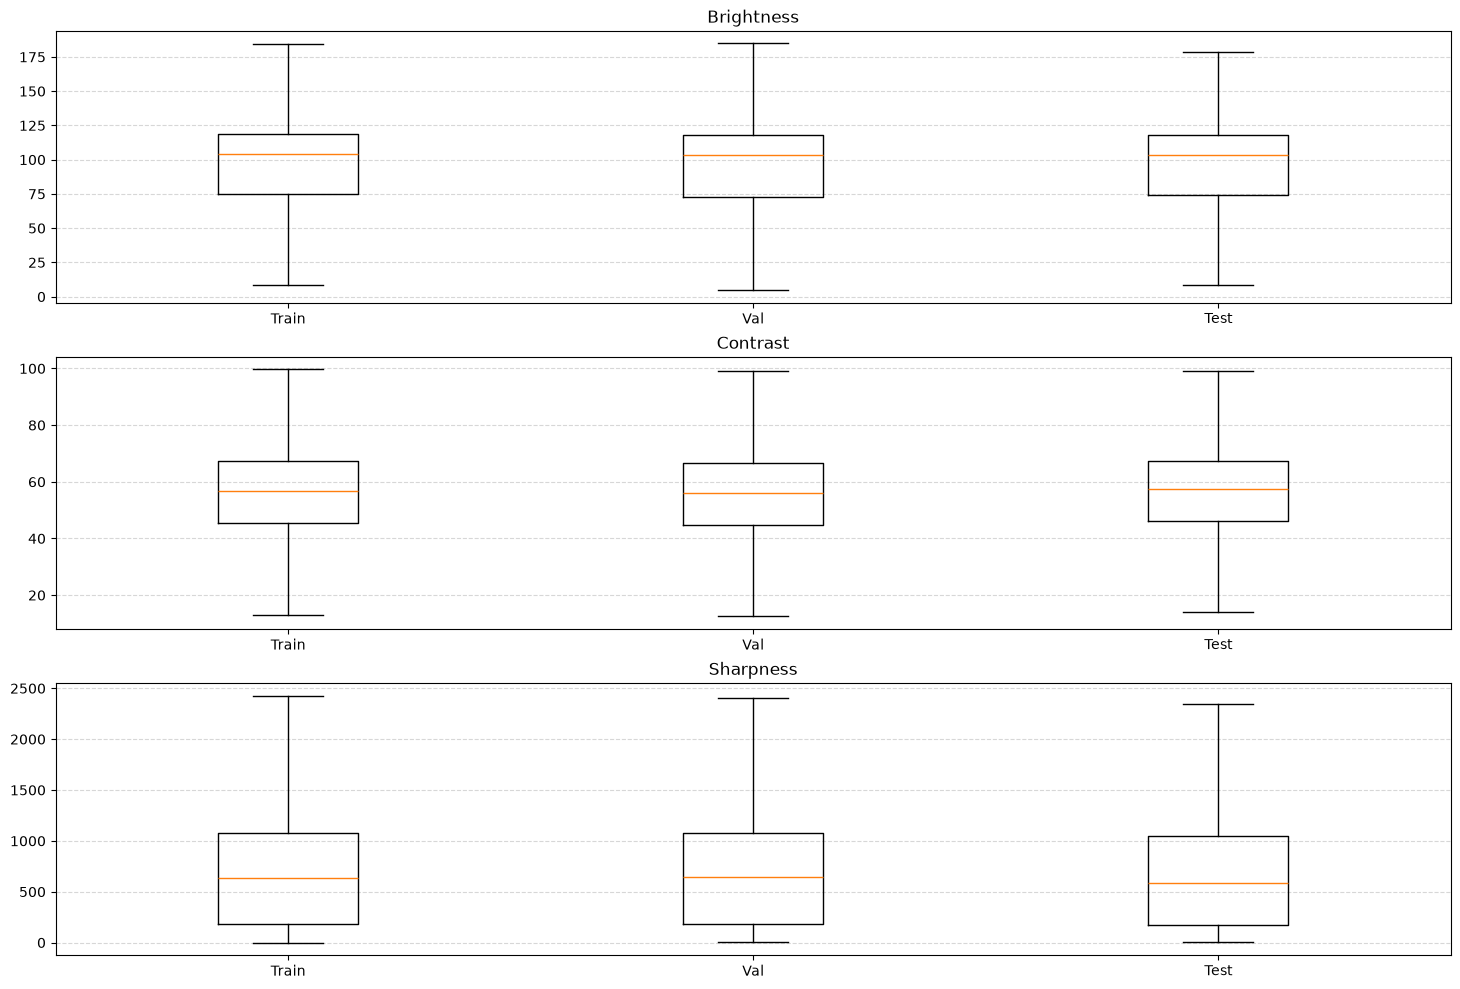

In [44]:
fig, axes = plt.subplots(3, 1, figsize=(18, 12))

for ax, prop in zip(axes, ["brightness", "contrast", "sharpness"]):
    ax.boxplot(
        [
            stats["global"][prop][stats["global"]["split"] == split]          
            for split in ["train", "val", "test"]
        ],
        tick_labels=["Train", "Val", "Test"],
        showfliers=False
    )

    ax.set_title(prop.capitalize())
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.savefig(PLOT_DIR / "image_props_by_split.svg")
plt.show()

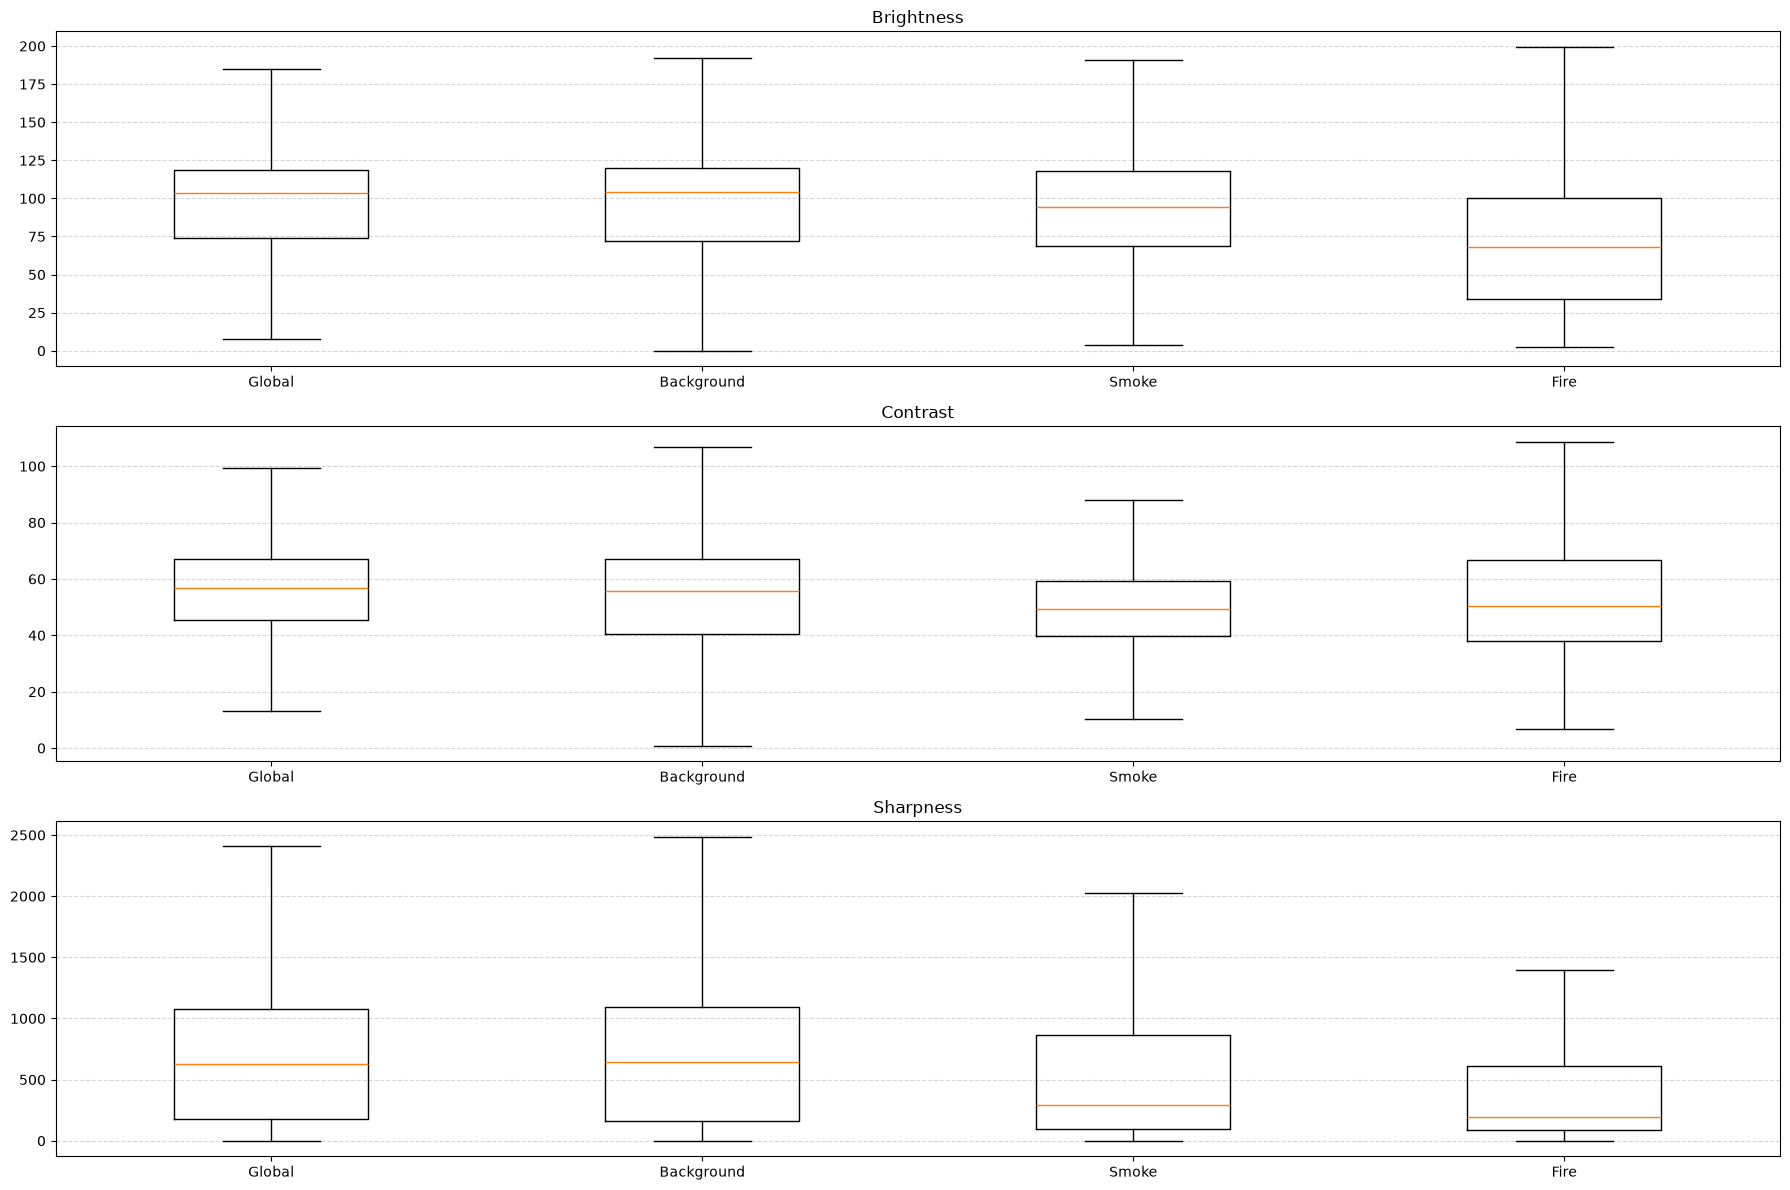

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(18, 12))

regions = ["global", "background", "smoke", "fire"]

for ax, prop in zip(axes, ["brightness", "contrast", "sharpness"]):
    ax.boxplot(
        [stats[region][prop].dropna() for region in regions],
        tick_labels=["Global", "Background", "Smoke", "Fire"],
        showfliers=False
    )

    ax.set_title(prop.capitalize())
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(PLOT_DIR / "regional_image_properties.svg")
plt.show()

In [46]:
class_data = {
    "fire": comparisons["fire"].loc[
        comparisons["fire"]["image_category"] == "fire_only"
    ].copy(),

    "smoke": comparisons["smoke"].loc[
        comparisons["smoke"]["image_category"] == "smoke_only"
    ].copy()
}

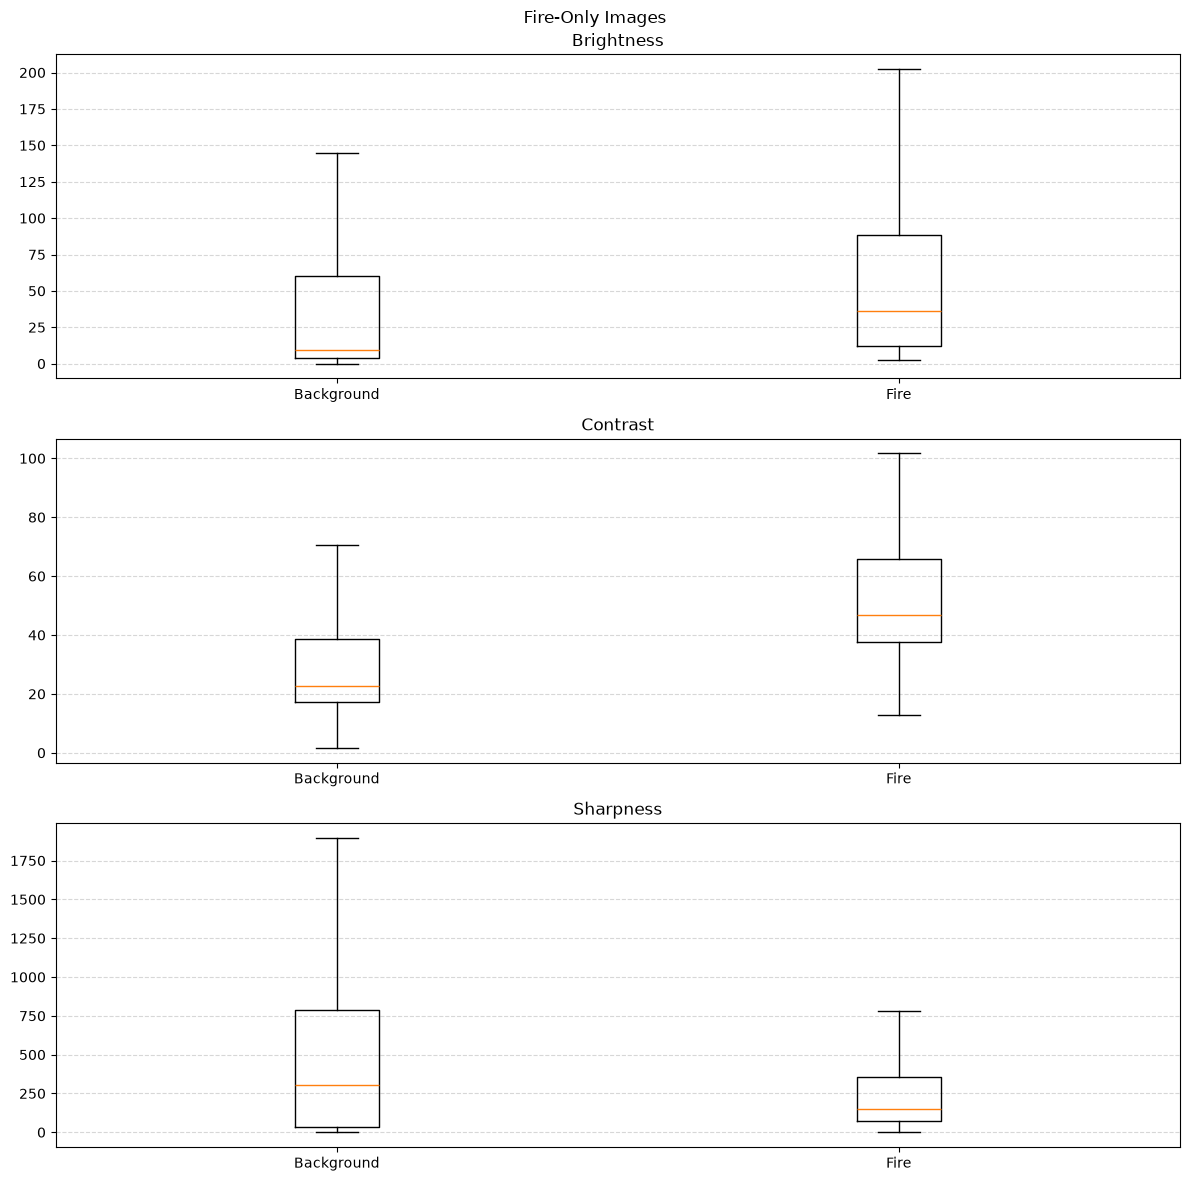

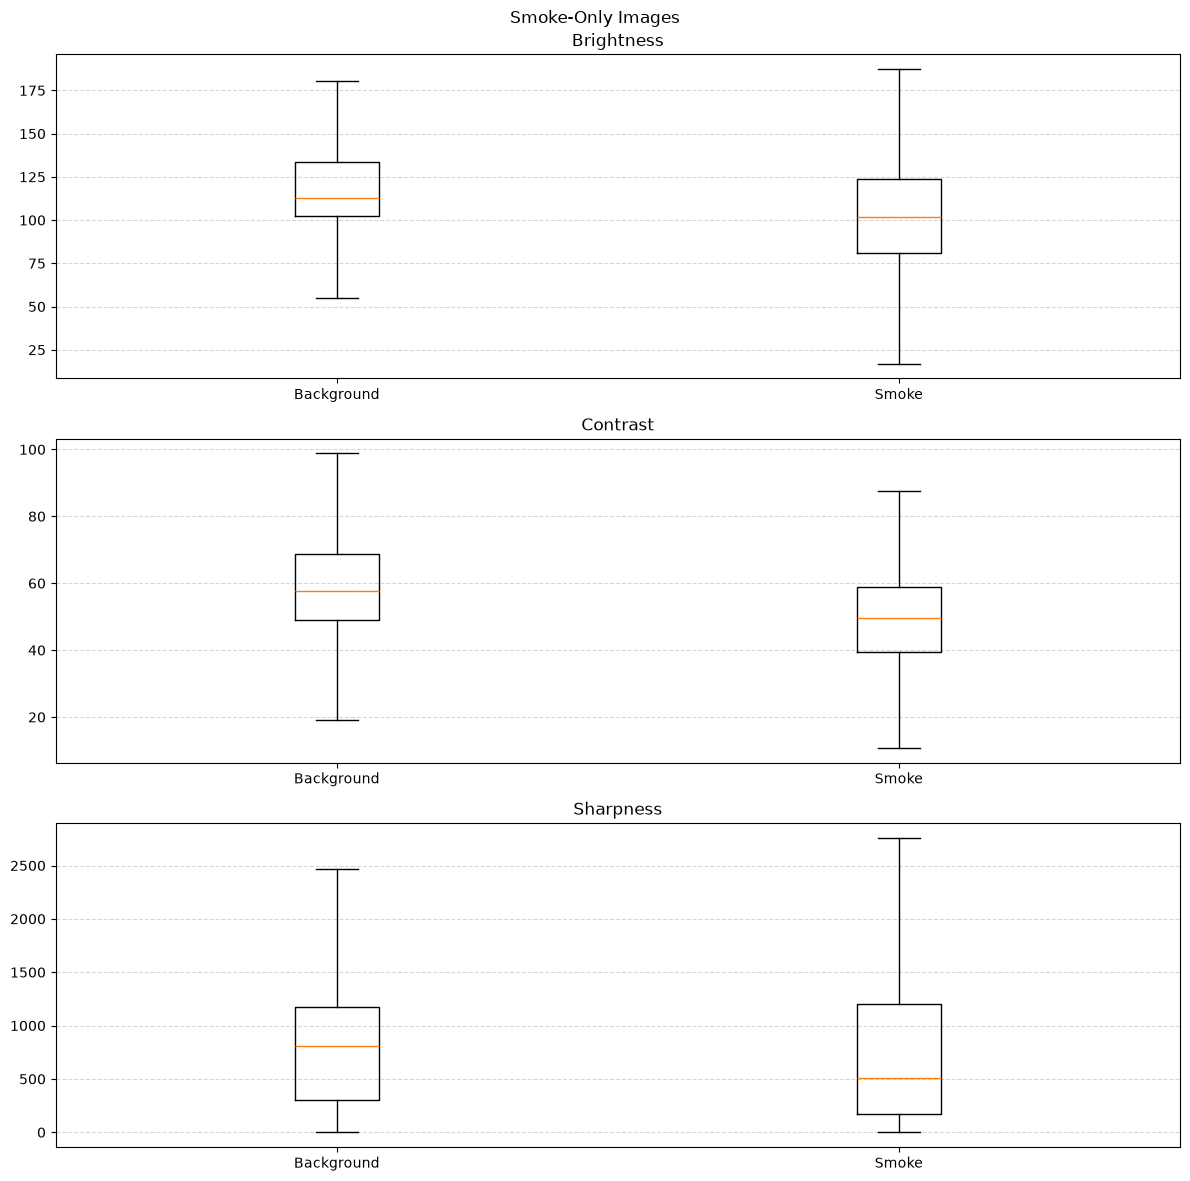

In [47]:
for region, data in class_data.items():
    fig, axes = plt.subplots(3, 1, figsize=(12, 12))

    for ax, prop in zip(axes, PROPS):
        ax.boxplot(
            [data[f"{prop}_background"], data[f"{prop}_{region}"]],
            tick_labels=["Background", region.capitalize()],
            showfliers=False
        )

        ax.set_title(prop.capitalize())
        ax.grid(axis="y", linestyle="--", alpha=0.5)

    fig.suptitle(f"{region.capitalize()}-Only Images")
    plt.tight_layout()
    fig.savefig(PLOT_DIR / f"{region}_only_properties.svg")
    plt.show()

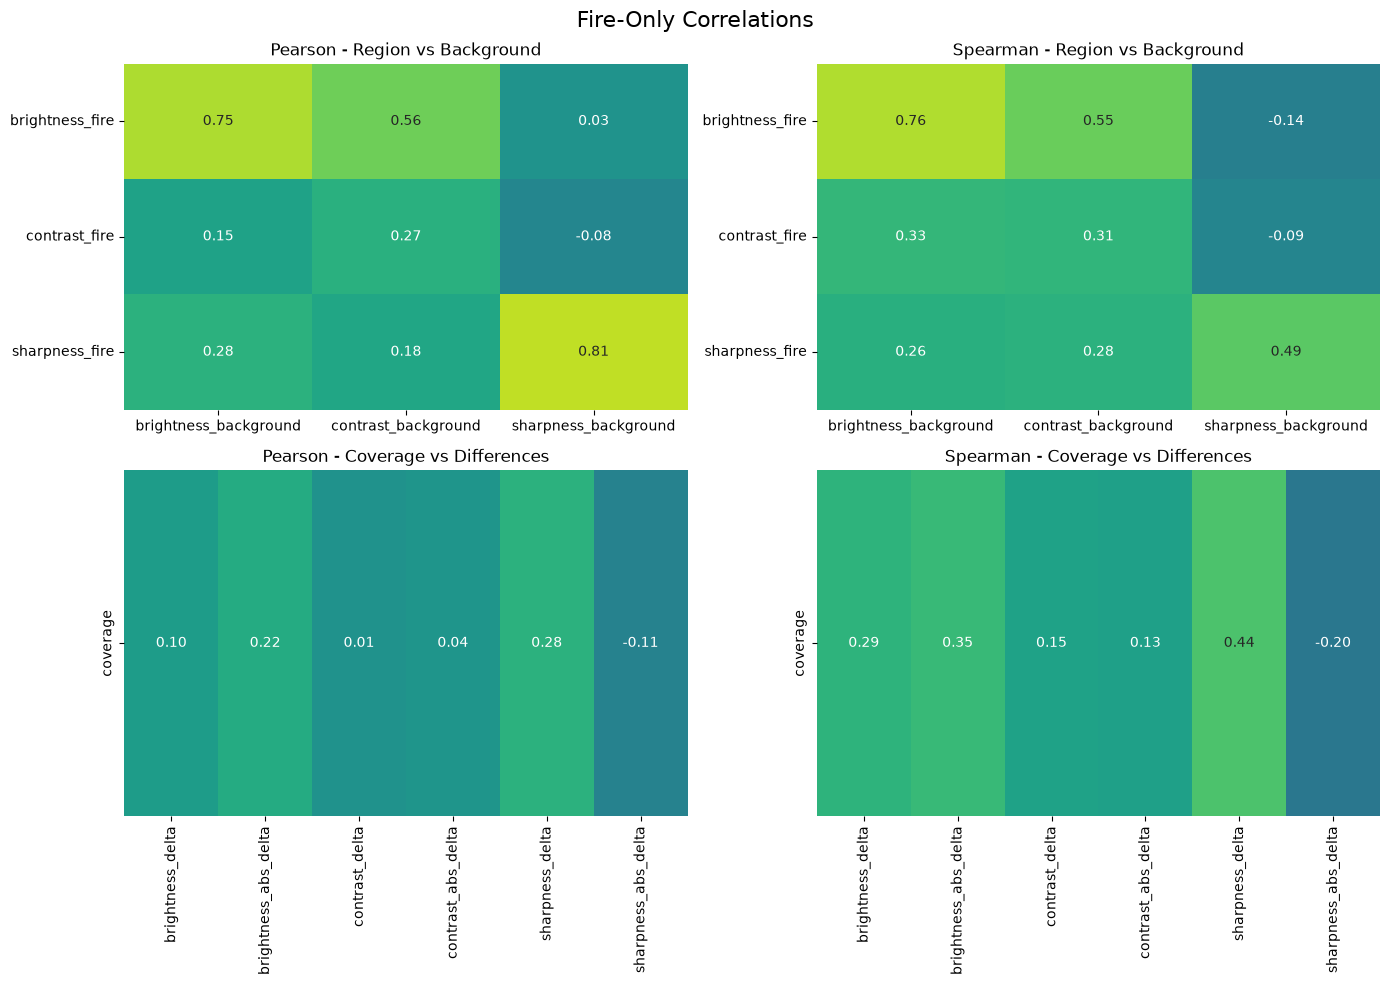

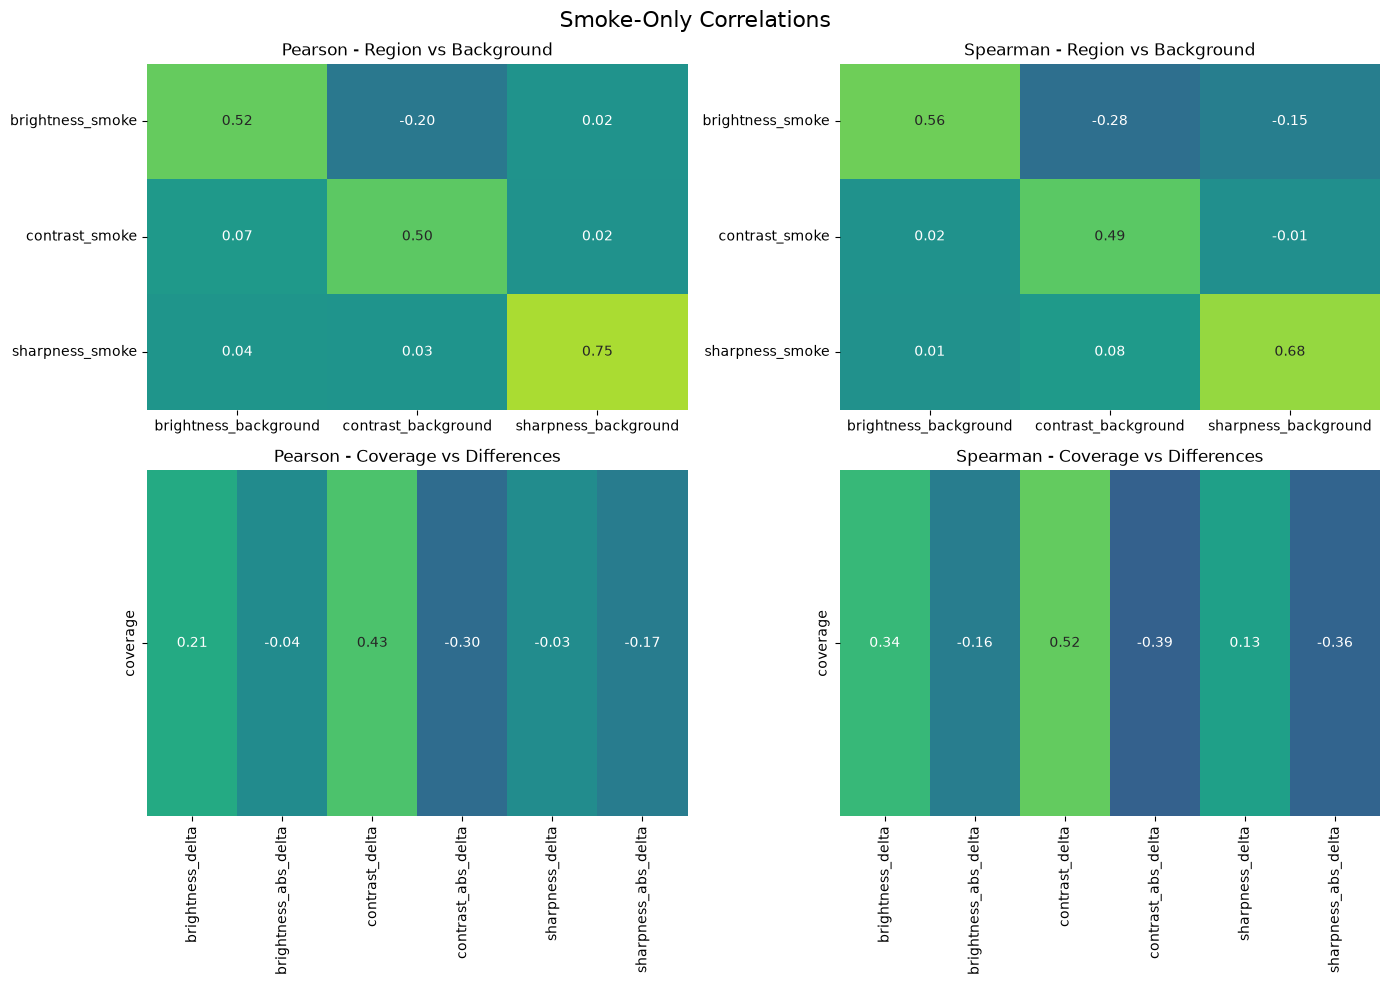

In [48]:
props = ["brightness", "contrast", "sharpness"]

for region, data in class_data.items():
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    for j, method in enumerate(["pearson", "spearman"]):
        corr = data.corr(method=method, numeric_only=True)

        # Regional properties vs background properties
        sns.heatmap(
            corr.loc[
                [f"{prop}_{region}" for prop in props],
                [f"{prop}_background" for prop in props]
            ],
            ax=axes[0, j],
            annot=True,
            fmt=".2f",
            cmap="viridis",
            vmin=-1,
            vmax=1,
            center=0,
            cbar=False
        )
        axes[0, j].tick_params(axis="x", labelrotation=0)
        axes[0, j].tick_params(axis="y", labelrotation=0)

        axes[0, j].set_title(f"{method.capitalize()} - Region vs Background")

        # Coverage vs differences
        sns.heatmap(
            corr.loc[
                ["coverage"],
                [f"{prop}_{suffix}"
                 for prop in props
                 for suffix in ("delta", "abs_delta")]
            ],
            ax=axes[1, j],
            annot=True,
            fmt=".2f",
            cmap="viridis",
            vmin=-1,
            vmax=1,
            center=0,
            cbar=False
        )

        axes[1, j].set_title(f"{method.capitalize()} - Coverage vs Differences")

    fig.suptitle(f"{region.capitalize()}-Only Correlations", fontsize=16)

    plt.tight_layout()
    fig.savefig(PLOT_DIR / f"{region}_only_correlations.svg")
    plt.show()

In [49]:
for region, data in class_data.items():
    print(f"\n{region.capitalize()}-only images")

    for prop in PROPS:
        delta = data[f"{prop}_delta"]

        print(
            f"{prop.capitalize()}: "
            f"{(delta > 0).mean():.1%} higher in {region} regions, "
            f"median delta = {delta.median():.2f}"
        )


Fire-only images
Brightness: 83.2% higher in fire regions, median delta = 11.39
Contrast: 84.5% higher in fire regions, median delta = 22.26
Sharpness: 55.4% higher in fire regions, median delta = 12.88

Smoke-only images
Brightness: 26.9% higher in smoke regions, median delta = -16.70
Contrast: 27.9% higher in smoke regions, median delta = -7.83
Sharpness: 43.5% higher in smoke regions, median delta = -41.32


In [50]:
print("Coverage vs background brightness")
for region, data in class_data.items():
    pearson = data["coverage"].corr(data["brightness_background"], method="pearson")
    spearman = data["coverage"].corr(data["brightness_background"], method="spearman")

    print(f"{region.capitalize()}: Pearson = {pearson:.3f}, Spearman = {spearman:.3f}")

Coverage vs background brightness
Fire: Pearson = 0.447, Spearman = 0.474
Smoke: Pearson = 0.240, Spearman = 0.300


`notebooks/data_books/04_correlation.ipynb`

In [51]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

# src/config/paths.py
DATASET_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

CSV_DIR = RESULTS_DIR / "csvs"
IMAGE_DIR = RESULTS_DIR / "images" 
PLOT_DIR = RESULTS_DIR / "plots" 
MODEL_DIR = RESULTS_DIR / "models"
WEIGHTS_DIR = MODEL_DIR / "weights"

ANALYSIS_DIR = CSV_DIR / "data_analysis"
IMAGE_DIR = IMAGE_DIR / "data_analysis"
PLOT_DIR = PLOT_DIR / "data_analysis"

In [52]:
image_stats = pd.read_csv(ANALYSIS_DIR/"image_properties.csv")
box_sizes = pd.read_csv(ANALYSIS_DIR/"box_sizes.csv")

In [53]:
combined = box_sizes.merge(
    image_stats,
    on="path",
    how="left",
    validate="many_to_one"
)

combined

,category_x,coordinates,xc,yc,width_x,height_x,path,area_x,split_x,width_y,height_y,area_y,brightness,sharpness,contrast,split_y,category_y
0,0,"[0.951171875, 0.18541666666666667, 0.057031250...",0.951172,0.185417,0.057031,0.093056,test/images/AoF06978.jpg,0.005307,test,1280,720,921600,105.654417,1087.601670,67.731629,test,smoke_only
1,0,"[0.33242187500000003, 0.40208333333333335, 0.0...",0.332422,0.402083,0.028906,0.031944,test/images/AoF07618.jpg,0.000923,test,1280,720,921600,107.496827,826.556759,54.652079,test,smoke_only
2,0,"[0.35781250000000003, 0.3590277777777778, 0.04...",0.357812,0.359028,0.040625,0.040278,test/images/AoF07673.jpg,0.001636,test,1280,720,921600,98.253279,1669.448280,69.176259,test,smoke_only
3,1,"[0.743359375, 0.6493055555555556, 0.1304687499...",0.743359,0.649306,0.130469,0.112500,test/images/AoF07718.jpg,0.014678,test,1280,720,921600,20.667310,476.972714,48.850509,test,both
4,1,"[0.46132812500000003, 0.6104166666666667, 0.04...",0.461328,0.610417,0.047656,0.098611,test/images/AoF07718.jpg,0.004699,test,1280,720,921600,20.667310,476.972714,48.850509,test,both
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26534,0,"[0.46990740740740733, 0.39254766031195837, 0.1...",0.469907,0.392548,0.194444,0.185442,val/images/WEB09436.jpg,0.036058,val,864,577,498528,57.009536,285.565703,46.006231,val,both
26535,0,"[0.41333333333333333, 0.29880952380952386, 0.5...",0.413333,0.298810,0.565333,0.526190,val/images/WEB09440.jpg,0.297473,val,750,420,315000,122.031584,287.240778,56.546569,val,smoke_only
26536,0,"[0.056666666666666664, 0.43809523809523815, 0....",0.056667,0.438095,0.100000,0.133333,val/images/WEB09440.jpg,0.013333,val,750,420,315000,122.031584,287.240778,56.546569,val,smoke_only
26537,0,"[0.5949579831932773, 0.43297587131367293, 0.79...",0.594958,0.432976,0.796639,0.833780,val/images/WEB09442.jpg,0.664222,val,595,373,221935,109.984635,197.015963,55.802025,val,both


In [54]:
print("Correlation between bounding box area and image area")

print("Pearson:", combined["area_x"].corr(combined["area_y"], method="pearson"))
print("Spearman:", combined["area_x"].corr(combined["area_y"], method="spearman"))

Correlation between bounding box area and image area
Pearson: -0.19002721498183395
Spearman: -0.2923119829155022


In [55]:
combined["box_count"] = combined.groupby("path")["path"].transform("size")

print("Correlation between box count and its area")

print("Pearson:", combined["box_count"].corr(combined["area_x"], method="pearson"))
print("Spearman:", combined["box_count"].corr(combined["area_x"], method="spearman"))

Correlation between box count and its area
Pearson: -0.1898926973740823
Spearman: -0.2874111459551712


In [56]:
# Just wondering does box count artificially increase/decrease the correlation in above checks 
image_boxes = combined.groupby("path").agg(
    mean_box_area=("area_x", "mean"),
    median_box_area=("area_x", "median"),
    max_box_area=("area_x", "max"),
    min_box_area=("area_x", "min"),
    box_count=("area_x", "size"),
    image_area=("area_y", "first")
)

image_boxes

,mean_box_area,median_box_area,max_box_area,min_box_area,box_count,image_area
path,,,,,,
test/images/AoF06978.jpg,0.005307,0.005307,0.005307,0.005307,1,921600
test/images/AoF07618.jpg,0.000923,0.000923,0.000923,0.000923,1,921600
test/images/AoF07673.jpg,0.001636,0.001636,0.001636,0.001636,1,921600
test/images/AoF07718.jpg,0.038528,0.011048,0.183644,0.004699,6,921600
test/images/AoF07719.jpg,0.048224,0.008789,0.203437,0.006699,5,921600
...,...,...,...,...,...,...
val/images/WEB09432.jpg,0.708169,0.708169,0.708169,0.708169,1,194400
val/images/WEB09433.jpg,0.889060,0.889060,0.889060,0.889060,1,174933
val/images/WEB09436.jpg,0.016131,0.004012,0.036058,0.001173,5,498528


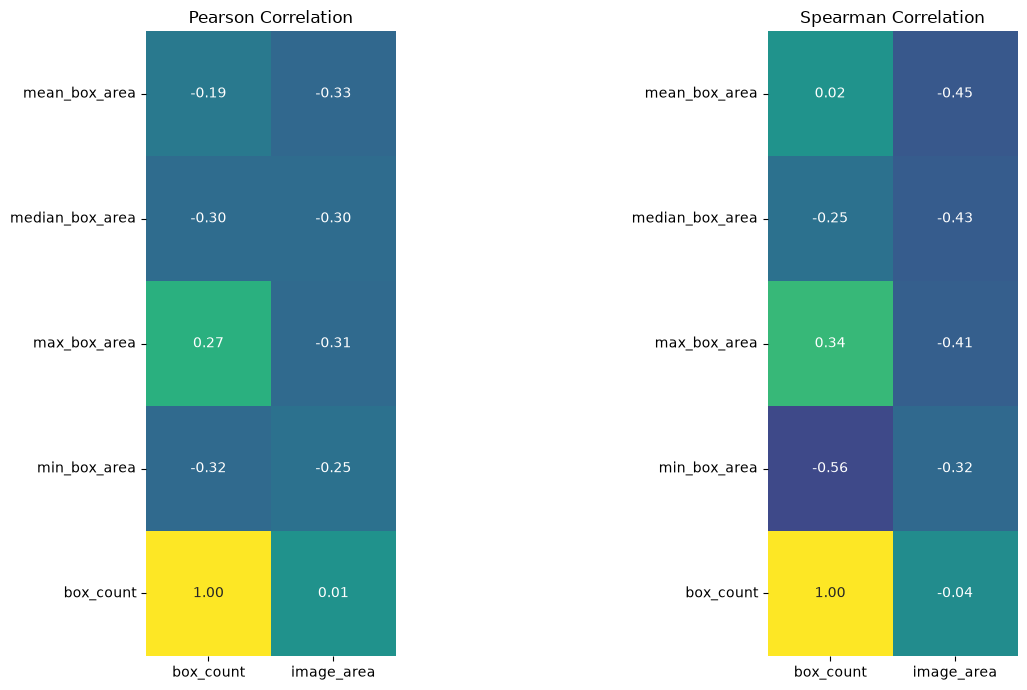

In [57]:
pears_corr = image_boxes.corr(method="pearson")
spear_corr = image_boxes.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, corr, title in zip(
    axes,
    [pears_corr, spear_corr],
    ["Pearson Correlation", "Spearman Correlation"]
):

    # Keep only correlations needed for image properties
    corr = corr.loc[
        ["mean_box_area", "median_box_area", "max_box_area",
            "min_box_area", "box_count"],
        ["box_count", "image_area"]
    ]

    sns.heatmap(
        corr,
        ax=ax,
        cbar=False,
        annot=True,
        vmin=-1,
        vmax=1,
        center=0,
        cmap="viridis",
        fmt=".2f",
        square=True,
        annot_kws={"size": 10}
    )

    ax.set_title(title)

plt.tight_layout()
plt.savefig(PLOT_DIR / "correlations.svg", bbox_inches="tight")
plt.show()

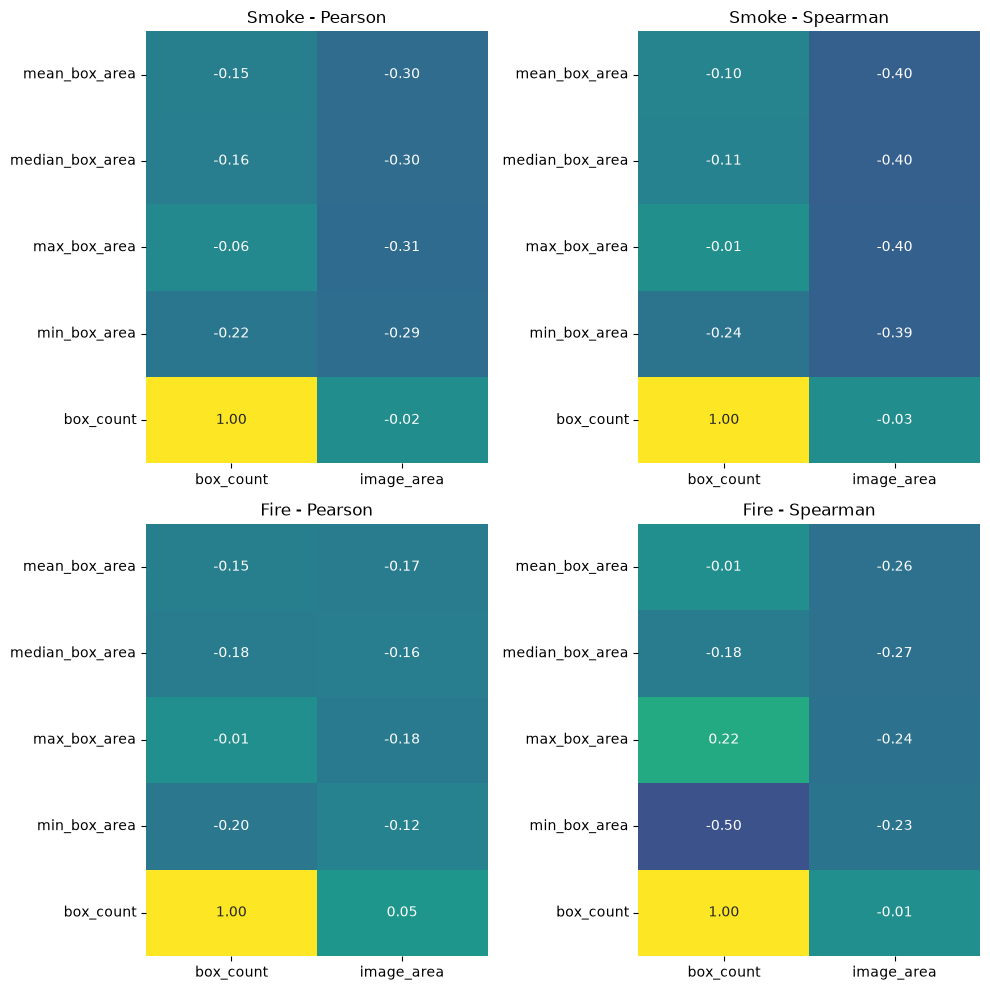

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for i, (category, name) in enumerate([(0, "Smoke"), (1, "Fire")]):
    subset = combined[combined["category_x"] == category]

    image_boxes = subset.groupby("path").agg(
        mean_box_area=("area_x", "mean"),
        median_box_area=("area_x", "median"),
        max_box_area=("area_x", "max"),
        min_box_area=("area_x", "min"),
        box_count=("area_x", "size"),
        image_area=("area_y", "first")
    )

    for j, method in enumerate(["pearson", "spearman"]):
        corr = image_boxes.corr(method=method)

        # Keep only correlations needed for image properties
        corr = corr.loc[
            ["mean_box_area", "median_box_area", "max_box_area",
             "min_box_area", "box_count"],
            ["box_count", "image_area"]
        ]

        sns.heatmap(
            corr,
            ax=axes[i, j],
            cbar=False,
            annot=True,
            vmin=-1,
            vmax=1,
            center=0,
            cmap="viridis",
            fmt=".2f",
            annot_kws={"size": 10}
        )

        axes[i, j].set_title(f"{name} - {method.capitalize()}")

plt.tight_layout()
plt.show()

### Pre-processing

*Code: Ciaran Whelan. Report: Preprocessing.*

`src/config/types.py`

In [59]:
import torch

import numpy as np

from dataclasses import dataclass, field
from typing import TypedDict, Callable

class ModelParameters(TypedDict):
    seed: int 
    num_workers: int
    pin_memory: bool

    batch_size: int
    epochs: int
    accumulation_steps: int

    learning_rate: float
    weight_decay: float

    model_name: str

class ModelInfo(TypedDict):
    timestamp: str
    notes: list[str]
    git_commit: str
    parameters: ModelParameters

@dataclass
class TrainingResults:
    history: ModelHistory
    best_state: dict[str, torch.Tensor] | None
    best_map50_95: float
    best_epoch: int | None
    error: Exception | None = None

@dataclass
class TrainingObjects:
    model: torch.nn.Module
    criterion: Callable
    optimizer: torch.optim.Optimizer 
    device: torch.device

    accumulation_steps: int
    scaler: torch.amp.GradScaler

    scheduler: torch.optim.lr_scheduler.LambdaLR | None = None # LambdaLR ensures consistent changes across different learning rates

@dataclass 
class EvaluationMetrics:
    # set by Trainer.evaluate, computed over the whole split
    map50: float
    map50_95: float 
    map_per_class: list[float] # [smoke, fire] 

    map_small: float 
    map_medium: float 
    map_large: float 

    mar_100: float
    mar_small: float 
    mar_medium: float 
    mar_large: float 

    recall50: float 
    recall50_small: float 
    recall50_medium: float 
    recall50_large: float 

    recall75: float 
    recall75_small: float 
    recall75_medium: float 
    recall75_large: float 

@dataclass
class EpochHistory:
    losses: list[float] = field(default_factory=list)
    metrics: list[float]  = field(default_factory=list)

    evaluation: EvaluationMetrics | None = None

    def append(self, loss, metrics):
        self.losses.append(loss)
        self.metrics.append(metrics)

    @property
    def avg_loss(self):
        return float(np.mean(self.losses)) if self.losses else 0.0

@dataclass
class ModelHistory:
    train: list[EpochHistory] = field(default_factory=list)
    eval: list[EpochHistory] = field(default_factory=list)

    def append(self, train_history, eval_history):
        self.train.append(train_history)
        self.eval.append(eval_history)

    @property
    def train_losses(self):
        return [batch_loss.avg_loss for batch_loss in self.train]
    
    @property
    def eval_losses(self):
        return [batch_loss.avg_loss for batch_loss in self.eval]
    
@dataclass
class BoundingBox:
    category: int   #Fire-1, Smoke-0
    coordinates: tuple[float, float, float, float] #x_center, y_center, width, height

`src/utils/device.py`

In [60]:
import torch

def get_device() -> torch.device:
    print(torch.__version__)
    print(torch.version.cuda)
    print(torch.cuda.is_available())
    print(torch.cuda.device_count())

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
    return device

`src/utils/parse_boxes.py`

In [61]:
def parse_boxes(boxes: list[dict]) -> list[BoundingBox]:
    return [
        BoundingBox(
            category=box["category"],
            coordinates=tuple(box["coordinates"])
        )
        for box in boxes
    ]

`src/utils/collate.py`

In [62]:
import torch

def collate_fn(batch):
    """Collates images and boxes into the format v8DetectionLoss expects

    Returns:
        images: torch.Tensor (B, 3, 640, 640)
        targets: dict
            batch_idx: (N, ) index of the image each box belongs to
            cls: (N, ) class of each box
            bboxes: (N, 4) x_center, y_center, width, height (normalised 0-1)
    """
    images, labels = zip(*batch)

    images = torch.stack(images)

    #prefix each box with the index of its image in the batch
    labels = torch.cat([
        torch.cat([torch.full((len(label), 1), i, dtype=label.dtype), label], dim=1)
        for i, label in enumerate(labels)
    ])

    return images, {
        "batch_idx": labels[:, 0],
        "cls": labels[:, 1],
        "bboxes": labels[:, 2:],
    }

`src/utils/eval_table.py`

In [63]:
def print_evaluation(history):
    m = history.evaluation

    print("\n" + "=" * 72)
    print(" " * 24 + "MODEL EVALUATION")
    print("=" * 72)

    print(f"\nOverall mAP50:     {m.map50:.4f}")
    print(f"Overall mAP50-95:  {m.map50_95:.4f}")

    print("\nDetection performance by object size")
    print("-" * 72)
    print(f"{'Size':<12} {'mAP':>12} {'mAR':>12} {'Recall@50':>14} {'Recall@75':>14}")
    print("-" * 72)

    rows = [
        ("Overall", m.map50_95, m.mar_100, m.recall50, m.recall75),
        ("Small", m.map_small, m.mar_small, m.recall50_small, m.recall75_small),
        ("Medium", m.map_medium, m.mar_medium, m.recall50_medium, m.recall75_medium),
        ("Large", m.map_large, m.mar_large, m.recall50_large, m.recall75_large),
    ]

    for name, ap, ar, r50, r75 in rows:
        print(f"{name:<12} {ap:>12.4f} {ar:>12.4f} {r50:>14.4f} {r75:>14.4f}")

    print("\nPer-class mAP50-95")
    print("-" * 72)

    for name, value in zip(("Smoke", "Fire"), m.map_per_class):
        print(f"{name:<12} {value:.4f}")

    print("=" * 72)

`src/utils/scheduler.py`

In [64]:
import numpy as np

T_max = 8 #FIXME find a way not ot hardcode this
min_factor = 0.1

def cosine_decay(epoch):
    progress = min(epoch / T_max, 1.0)

    return min_factor + (1 - min_factor) * (
        1 + np.cos(np.pi * progress)
    ) / 2

`src/utils/get_mean.py`

In [65]:
def mean_valid(values):
    valid = values[values >= 0]
    return valid.mean().item() if valid.numel() else float("nan")

`src/data/preprocessing/dataset.py`

In [66]:
import torch
from torchvision.transforms import functional as F
from torch.utils.data import Dataset

from PIL import Image

def letterbox(img, labels, size=640):
    width, height = img.size

    # Preserve aspect ratio
    scale = min(size / width, size / height)

    new_width = round(width * scale)
    new_height = round(height * scale)

    # Resize image
    img = F.resize(img, [new_height, new_width])

    # Calculate padding
    pad_left = (size - new_width) // 2
    pad_top = (size - new_height) // 2
    pad_right = size - new_width - pad_left
    pad_bottom = size - new_height - pad_top

    img = F.pad(
        img,
        [pad_left, pad_top, pad_right, pad_bottom],
        fill=114,
    )

    # Transform normalised YOLO coordinates
    if labels.numel() > 0:
        labels = labels.clone()

        labels[:, 1] = (
            labels[:, 1] * new_width + pad_left
        ) / size

        labels[:, 2] = (
            labels[:, 2] * new_height + pad_top
        ) / size

        labels[:, 3] *= new_width / size
        labels[:, 4] *= new_height / size

    return img, labels

class ModelData(Dataset):
    def __init__(
            self, 
            root, 
            data, # tuple[paths, coordinates] 
            transform,
            flip_prob = 0.0,
            zoom_prob = 0.0,
            zoom_max = 1.3
        ):
        self.root = root
        self.data = data
        self.transform = transform

        self.flip_prob = flip_prob
        self.zoom_prob = zoom_prob
        self.zoom_max = zoom_max

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx: int):
        path, boxes = self.data[idx] 
        img = Image.open(self.root / path).convert("RGB")

        # (N, 5): class, x_center, y_center, width, height (normalised 0-1)
        # reshape keeps images with no boxes as (0,5) instead of (0,)
        labels = torch.tensor(
            [[box.category, *box.coordinates] for box in boxes],
            dtype=torch.float32,
        ).reshape(-1, 5)

        img, labels = letterbox(img, labels, size=768)

        img = self.transform(img)

        # Random horizontal flip
        if torch.rand(1).item() < self.flip_prob:
            img = F.hflip(img)

            labels[:, 1] = 1.0 - labels[:, 1]

        # Random zoom-in
        if torch.rand(1).item() < self.zoom_prob:
            zoom = 1.0 + torch.rand(1).item() * (self.zoom_max - 1.0)

            _, H, W = img.shape

            crop_h = max(1, round(H / zoom))
            crop_w = max(1, round(W / zoom))

            # randomally chosen top left to start from
            top = torch.randint(0, H - crop_h + 1, (1,)).item()
            left = torch.randint(0, W - crop_w + 1, (1,)).item()

            img = F.resized_crop(
                img,
                top=top,
                left=left,
                height=crop_h,
                width=crop_w,
                size=[H, W],
                antialias=True,
            )

            if len(labels) > 0:
                # Convert normalised YOLO boxes into pixel xyxy coordinates
                xyxy = torch.stack([
                    (labels[:, 1] - labels[:, 3] / 2) * W,
                    (labels[:, 2] - labels[:, 4] / 2) * H,
                    (labels[:, 1] + labels[:, 3] / 2) * W,
                    (labels[:, 2] + labels[:, 4] / 2) * H,
                ], dim=1)

                # Translate coordinates into the cropped image
                xyxy[:, [0, 2]] -= left
                xyxy[:, [1, 3]] -= top

                # Clip boxes to crop boundaries
                xyxy[:, [0, 2]] = xyxy[:, [0, 2]].clamp(0, crop_w)
                xyxy[:, [1, 3]] = xyxy[:, [1, 3]].clamp(0, crop_h)

                # Remove boxes that are entirely outside the crop
                valid = (
                    (xyxy[:, 2] > xyxy[:, 0]) &
                    (xyxy[:, 3] > xyxy[:, 1])
                )

                labels = labels[valid]
                xyxy = xyxy[valid]

                # Convert back to normalised YOLO coordinates
                labels[:, 1] = (xyxy[:, 0] + xyxy[:, 2]) / (2 * crop_w)
                labels[:, 2] = (xyxy[:, 1] + xyxy[:, 3]) / (2 * crop_h)
                labels[:, 3] = (xyxy[:, 2] - xyxy[:, 0]) / crop_w
                labels[:, 4] = (xyxy[:, 3] - xyxy[:, 1]) / crop_h

        return img, labels

`src/data/preprocessing/transforms.py`

In [67]:
from torchvision import transforms

# resize only so the normalised box coordinates stay valid
train_transform = transforms.Compose([
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.015, # small hue shift so fire keeps its color (YOLO default)
    ),
    transforms.ToTensor(),
    # bacbone is pretrained in ImageNet so keep its normalisation
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], # Colour channels from ImageNet
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

## 2. The Network Structure

*Code: Emma O'Reilly and Ciaran Whelan. Report: Network Structure.*

`src/fine_tune/models/resnet.py`

In [68]:
import torch
import torch.nn as nn

class Block(nn.Module):
    """
    ResNet-50 V1.5 bottleneck block.

    Main branch:
        1x1 Conv: in_channels -> width
        3x3 Conv: width -> width, optional space reduction
        1x1 Conv: width -> 4 * width

    Each convolution is followed by BatchNorm.
    ReLU follows the first two BatchNorm layers.

    Shortcut:
        Identity when input/output dimensions match.
        1x1 projection + BatchNorm otherwise.

    The branches are added, followed by ReLU.

    Input:
        (B, in_channels, H, W)

    Output:
        (B, 4 * width, H/stride, W/stride)
    """
    expansion = 4 

    def __init__(self, in_channels, width, stride=1):
        super().__init__()

        out_channels = width * self.expansion

        # In: (B, in_channels, H, W)
        # 1x1 conv changes in_channels -> width
        # stride=1 keeps H and W the same
        # Out: (B, width, H, W) 
        self.conv1 = nn.Conv2d(
            in_channels, width, 
            kernel_size=1, stride=1, 
            bias=False
        )
        self.batch1 = nn.BatchNorm2d(width)

        # In: (B, width, H, W)
        # 3x3 conv preserves the width
        # padding=1 preserves H and W when stride=1
        # stride=2 downsizes H -> H/2 and W -> W/2
        # Out: (B, width, H/stride, W/stride)
        self.conv2 = nn.Conv2d(
            width, width, 
            kernel_size=3, stride=stride, padding=1, 
            bias=False
        )
        self.batch2 = nn.BatchNorm2d(width)

        # In: (B, width, H, W)
        # 1x1 conv expands width -> 4 * width
        # Out: (B, out_channels, H, W)
        self.conv3 = nn.Conv2d(
            width, out_channels, 
            kernel_size=1, stride=1, 
            bias=False
        )
        self.batch3 = nn.BatchNorm2d(out_channels)

        self.activation = nn.ReLU(inplace=True) # inplace reduces memory usage 

        # Presevrs (B, in_channels, H, W)
        self.shortcut = nn.Identity()

        if stride != 1 or in_channels != out_channels:
            # Projection convert in_channels -> out_channels
            # Uses same stride as conv2 to match H and W
            # Out: (B, out_channels, H/stride, W/stride)
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 
                    kernel_size=1, stride=stride, 
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        identity = self.shortcut(x)

        features = self.conv1(x)
        features = self.batch1(features)
        self.activation(features)

        features = self.conv2(features)
        features = self.batch2(features)
        self.activation(features)

        features = self.conv3(features)
        features = self.batch3(features)

        features = features + identity
        self.activation(features)

        return features

class Stem(nn.Module):
    """
    Initial feature extraction and downsampling for ResNet-50.

    Input: (B, in_channels, H, W)

    Operations:
        7x7 Conv:   in_channels -> out_channels, H/2 x W/2
        BatchNorm
        ReLU
        3x3 MaxPool: Preserves channels, H/4 x W/4

    Output: (B, out_channels, H/4, W/4)

    For a 640x640 RGB input:
        (B, 3, 640, 640) -> (B, 64, 160, 160)
    """

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels, out_channels, 
            kernel_size=7, stride=2, padding=3, 
            bias=False
        )
        self.batch = nn.BatchNorm2d(out_channels)
        self.activation = nn.ReLU(inplace=True)

        self.max_pool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        features = self.conv(x)
        features = self.batch(features)
        self.activation(features)

        return self.max_pool(features)

class ResNetBackbone(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.stem = Stem(in_channels=3, out_channels=64)

        # 1 conv block, 2 identity
        self.stage1 = nn.Sequential(
            Block(64, 64), # conv_block as in != out
            Block(256, 64),
            Block(256, 64)
        )

        # 1 conv block, 3 identity
        self.stage2 = nn.Sequential(
            Block(256, 128, stride=2),
            Block(512, 128),
            Block(512, 128),
            Block(512, 128)
        )

        # 1 conv block, 5 identity
        self.stage3 = nn.Sequential(
            Block(512, 256, stride=2),
            Block(1024, 256),
            Block(1024, 256),
            Block(1024, 256),
            Block(1024, 256),
            Block(1024, 256)
        )

        # 1 conv block, 2 identity
        self.stage4 = nn.Sequential(
            Block(1024, 512, stride=2),
            Block(2048, 512),
            Block(2048, 512)
        )

    def forward(self, x):  # Input: 640 x 640 x 3
        # Output for each part : H x W x C
        x = self.stem(x) # 160 x 160 x 64
        x = self.stage1(x) # 160 x 160 x 256

        p3 = self.stage2(x) # 80 x 80 x 512
        p4 = self.stage3(p3) # 40 x 40 x 1024
        p5 = self.stage4(p4) # 20 x 20 x 2048

        return p3, p4, p5

`scripts/training/convert_weights.py`

Reuses: torchvision ImageNet ResNet-50 weights (`IMAGENET1K_V2`)

Changed: only runs if the weights aren't saved yet (was `if __name__ == "__main__":`).

In [69]:
from pathlib import Path
import torch
from torchvision.models import ResNet50_Weights

"""
python -m scripts.training.convert_weights
"""

def map_resnet_weights(state_dict):
    mapped = {}

    for key, value in state_dict.items():
        if key.startswith("fc."): # Skips weights in the final classifier
            continue

        if key.startswith("conv1."):
            key = key.replace("conv1.", "stem.conv.", 1)

        elif key.startswith("bn1."):
            key = key.replace("bn1.", "stem.batch.", 1)

        else:
            for i in range(1, 5):
                key = key.replace(f"layer{i}.", f"stage{i}.", 1)

            key = key.replace(".bn1.", ".batch1.")
            key = key.replace(".bn2.", ".batch2.")
            key = key.replace(".bn3.", ".batch3.")
            key = key.replace(".bn4.", ".batch4.")
            key = key.replace(".downsample.", ".shortcut.")

        mapped[key] = value

    return mapped

if not (WEIGHTS_DIR / "resnet50.pt").exists():
    weights = ResNet50_Weights.IMAGENET1K_V2

    state_dict = torch.hub.load_state_dict_from_url(
        weights.url,
        map_location="cpu"
    )

    mapped_weights = map_resnet_weights(state_dict)

    # Verify compatibility before saving
    backbone = ResNetBackbone()
    backbone.load_state_dict(mapped_weights, strict=True)

    WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
    torch.save(mapped_weights, WEIGHTS_DIR / "resnet50.pt")

`src/fine_tune/models/hybrid.py`

Reuses: Ultralytics `C2f`, `Conv` and `Detect` (YOLOv8 neck and head)

In [70]:
import torch
import torch.nn as nn
from ultralytics.nn.modules import C2f, Conv, Detect

class HybridModel(nn.Module):
    def __init__(self, num_classes=2, widths=(128, 256, 512)):
        super().__init__()
        c3, c4, c5 = widths

        self.backbone = ResNetBackbone()

        # 1x1 conv: ResNet channels 512, 1024, 2048 -> YOLO widths
        self.adapter = nn.ModuleList(Conv(c_in, c_out) for c_in, c_out in zip((512, 1024, 2048), widths))

        #YOLOv8 neck (FPN top-down + PAN bottom-up)
        self.upsample = nn.Upsample(scale_factor=2, mode="nearest")
        self.top_down4 = C2f(c5 + c4, c4)
        self.top_down3 = C2f(c4 + c3, c3)
        self.downsample3 = Conv(c3, c3, 3, 2)
        self.bottom_up4 = C2f(c3 + c4, c4)
        self.downsample4 = Conv(c4, c4, 3, 2)
        self.bottom_up5 = C2f(c4 + c5, c5)

        self.detect = Detect(nc=num_classes, ch=widths)
        self.detect.stride = torch.tensor([8.0, 16.0, 32.0])
        self.detect.bias_init()

        self._intitialise_weights()

    def forward(self, x):
        p3, p4, p5 = (adapt(f) for adapt, f in zip(self.adapter, self.backbone(x)))

        t4 = self.top_down4(torch.cat([self.upsample(p5), p4], 1))
        n3 = self.top_down3(torch.cat([self.upsample(t4), p3], 1))
        n4 = self.bottom_up4(torch.cat([self.downsample3(n3), t4], 1))
        n5 = self.bottom_up5(torch.cat([self.downsample4(n4), p5], 1))

        return self.detect([n3, n4, n5])

    def _intitialise_weights(self):
        self.backbone.load_state_dict(
            torch.load(
                WEIGHTS_DIR / "resnet50.pt", 
                map_location="cpu", 
                weights_only=True
                )
            )
        

## 3. Loss Function, Optimiser and Cross-Fold Validation

### Loss function and optimiser

*Code: Emma O'Reilly and Ciaran Whelan. Report: Loss Function, Optimiser.*

`src/fine_tune/losses/base.py`

In [71]:
import torch

from abc import ABC, abstractmethod

class BaseLoss(ABC):

    @abstractmethod
    def loss(self, predicts, target):
        pass

    def metrics(self, predicts, target):
        return {}

    def __call__(self, predicts, target):
        loss = self.loss(predicts, target)

        with torch.no_grad():
            metrics = self.metrics(predicts, target)

        return loss, metrics

`src/fine_tune/losses/yolo.py`

Reuses: Ultralytics `v8DetectionLoss`

In [72]:
from types import SimpleNamespace
from ultralytics.utils.loss import v8DetectionLoss

class YOLOLoss(BaseLoss):
    def __init__(self, model) -> None:
        shim = SimpleNamespace(
            args=SimpleNamespace(box=7.5, cls=0.5, dfl=1.5), #ulatrlytics default gains
            model=[model.detect],
            parameters=model.parameters,
        )
        self.criterion = v8DetectionLoss(shim)

    def loss(self, predicts, target):
        return self(predicts, target)[0]

    def __call__(self, predicts, target):
        # one pass gives both the total and the separate box/cls/dfl terms
        total, items = self.criterion(predicts, target)
        return total.sum(), {name: value.item() for name, value in items.items()}

`src/fine_tune/train.py`

Reuses: Ultralytics `non_max_suppression`, torchmetrics `MeanAveragePrecision`, torchvision `box_convert`

In [73]:
import torch
from torch.optim.lr_scheduler import LambdaLR

import numpy as np
import pandas as pd

import time
from tqdm.auto import tqdm

import json
from copy import deepcopy
from collections import deque

from torchmetrics.detection import MeanAveragePrecision
from torchvision.ops import box_convert
from ultralytics.utils.nms import non_max_suppression

class Trainer:
    def __init__(self, objs: TrainingObjects):
        self.objs = objs

    def train_one_epoch(self, dataloader):
        model = self.objs.model
        criterion = self.objs.criterion
        optimizer = self.objs.optimizer
        device = self.objs.device
        accum_steps = self.objs.accumulation_steps
        scaler = self.objs.scaler
        scheduler = self.objs.scheduler

        model.train()

        num_batches = len(dataloader)
        if num_batches == 0:
            raise RuntimeError("Training dataloader produced no batches")

        history = EpochHistory()
        optimizer.zero_grad()
        for i, (imgs, coords) in enumerate(dataloader):
            imgs = imgs.to(device)

            batch_start = (i // accum_steps) * accum_steps  # gets lowest starting value 
            batch_size = min(accum_steps, num_batches - batch_start)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(imgs)
                loss, metrics = criterion(outputs, coords)

            scaler.scale(loss / batch_size).backward()

            # gradient accumulation, lets it simulate larger batches
            if (i + 1) % accum_steps == 0 or (i + 1) == num_batches:
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

            history.append(loss.item(), metrics)

        if scheduler is not None:
            scheduler.step()
        
        return history

    @torch.inference_mode()
    def evaluate(self, dataloader):
        model = self.objs.model
        criterion = self.objs.criterion
        device = self.objs.device

        if len(dataloader) == 0:
            raise RuntimeError("Evaluation dataloader produced no batches")

        model.eval()

        # COCO-style mAP over the whole split, class_metrics gives fire and smoke separately
        map_metrics = MeanAveragePrecision(
            box_format="xyxy", iou_type="bbox", 
            class_metrics=True,  extended_summary=True,
            max_detection_thresholds=[1, 10, 100]
        )

        history = EpochHistory()
        for imgs, targets in dataloader:
            imgs = imgs.to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                outputs = model(imgs) # eval mode: (decoded boxes, raw predictions)
                loss, metrics = criterion(outputs, targets)

            history.append(loss.item(), metrics)

            # same thresholds Ultralytics validates with, low conf keeps every recall level
            detections = non_max_suppression(outputs, conf_thres=0.001, iou_thres=0.7, max_det=300)

            predictions = [
                {
                    "boxes": det[:, :4].float().cpu(),
                    "scores": det[:, 4].float().cpu(),
                    "labels": det[:, 5].long().cpu(),
                }
                for det in detections
            ]
            map_metrics.update(predictions, self._ground_truth(targets, len(imgs), imgs.shape[-2:]))

        results = map_metrics.compute()
        recall = results["recall"]

        history.evaluation = EvaluationMetrics(
            map50 = results["map_50"].item(),
            map50_95 = results["map"].item(),
            map_per_class = results["map_per_class"].tolist(),

            map_small = results["map_small"].item(),
            map_medium = results["map_medium"].item(),
            map_large = results["map_large"].item(),

            mar_100 = results["mar_100"].item(),
            mar_small = results["mar_small"].item(),
            mar_medium = results["mar_medium"].item(),
            mar_large = results["mar_large"].item(),

            recall50 = mean_valid(recall[0, :, 0, 2]),
            recall50_small = mean_valid(recall[0, :, 1, 2]),
            recall50_medium = mean_valid(recall[0, :, 2, 2]),
            recall50_large = mean_valid(recall[0, :, 3, 2]),

            recall75 = mean_valid(recall[5, :, 0, 2]),
            recall75_small = mean_valid(recall[5, :, 1, 2]),
            recall75_medium = mean_valid(recall[5, :, 2, 2]),
            recall75_large = mean_valid(recall[5, :, 3, 2]),
        )
      
        return history

    @staticmethod
    def _ground_truth(targets, batch_size, image_size):
        """Converts collated targets to per-image pixel xyxy boxes for MeanAveragePrecision

        targets["bboxes"] are normalised x_center, y_center, width, height
        predictions from NMS are pixel x1, y1, x2, y2 so the targets are scaled to match
        """
        height, width = image_size
        scale = torch.tensor([width, height, width, height])
        boxes = box_convert(targets["bboxes"] * scale, in_fmt="cxcywh", out_fmt="xyxy")

        return [
            {
                "boxes": boxes[targets["batch_idx"] == i],
                "labels": targets["cls"][targets["batch_idx"] == i].long(),
            }
            for i in range(batch_size)
        ]

    def train_model(
            self, 
            epochs: int,
            train_loader,
            val_loader
        ):
        if epochs == 0:
            raise ValueError("Cannot train model for 0 epochs")

        best_map50_95 = float("-inf")
        best_epoch = None
        best_state = None

        # Window of recent losses to see if there is none/minimal change
        eval_window = deque(maxlen=5)
        decreased_lr = False

        pbar = tqdm(total=epochs, desc="Training")

        history = ModelHistory()
        try:
            for epoch in range(epochs):
                torch.cuda.reset_peak_memory_stats()
                start = time.perf_counter()
                train_history = self.train_one_epoch(train_loader)
                train_time = time.perf_counter() - start
                vram = f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GiB"

                start = time.perf_counter()
                eval_history = self.evaluate(val_loader)
                eval_time = time.perf_counter() - start

                eval_loss = eval_history.avg_loss
                train_loss = train_history.avg_loss

                history.append(train_history, eval_history)
                
                if eval_history.evaluation.map50_95 > best_map50_95:
                    best_map50_95 = eval_history.evaluation.map50_95
                    best_epoch = epoch + 1

                    # TODO may need to be changed as it keeps the model on VRAM will verify
                    best_state = deepcopy(self.objs.model.state_dict())

                tqdm.write(
                    f"Epoch {epoch + 1:02d} | "
                    f"Train loss {train_loss:.4f} | "
                    f"Eval loss {eval_loss:.4f} | "
                    f"Gap {abs(eval_loss - train_loss):.4f} | "
                    f"mAP50 {eval_history.evaluation.map50:.3f} | "
                    f"mAP50-95 {eval_history.evaluation.map50_95:.3f} | "
                    f"Train time {train_time:.2f} | "
                    f"Eval time {eval_time:.2f} | "
                    f"VRAM usage {vram} | " 
                )

                pbar.update(1)

                eval_window.append(eval_loss)
                # Early stopping mechanism
                if len(eval_window) == eval_window.maxlen:
                    window = np.asarray(eval_window)

                    x = np.arange(len(window))
                    # y = mx + c where y = window
                    slope = np.polyfit(x, window, 1)[0] # polyfit returns [m, c]

                    relative_slope = slope / (abs(window.mean()) + 1e-8)
                    # if it doesnt improve by more than -0.1% stop training
                    if relative_slope > -1e-3:
                        if not decreased_lr:
                            for group in self.objs.optimizer.param_groups:
                                group["lr"] *= 0.5

                            decreased_lr = True
                            eval_window.clear()

                            self.objs.scheduler = LambdaLR(self.objs.optimizer, lr_lambda=cosine_decay) 
                            tqdm.write(
                                f"Validation loss plateau detected. Reducing LR to {self.objs.optimizer.param_groups[0]['lr']:.2e}"
                            )
                            continue
                        break

            if best_state is None or best_epoch is None:
                raise RuntimeError("Training completed without a valid validation result")

        except Exception as e:
            return TrainingResults(
                history=history,
                best_state=best_state,
                best_map50_95=best_map50_95,
                best_epoch=best_epoch,
                error=e
            )
        finally:
            pbar.close()

        return TrainingResults(
            history=history,
            best_state=best_state,
            best_map50_95=best_map50_95,
            best_epoch=best_epoch,
            )

    @staticmethod
    def save_results(results, model_info, timestamp):
        EXPER_DIR = MODEL_DIR / timestamp
        EXPER_DIR.mkdir(parents=True, exist_ok=True)

        with open(EXPER_DIR / "metadata.json", "w") as f:
            json.dump(model_info, f, indent=4)

        rows = [
            {
            "epoch": epoch,
            "train_loss": train.avg_loss,
            "val_loss": val.avg_loss,
            
            "map50": val.evaluation.map50,
            "map50_95": val.evaluation.map50_95,
            "map_small": val.evaluation.map_small,
            "map_medium": val.evaluation.map_medium,
            "map_large": val.evaluation.map_large,

            "mar_100": val.evaluation.mar_100,
            "mar_small": val.evaluation.mar_small,
            "mar_medium": val.evaluation.mar_medium,
            "mar_large": val.evaluation.mar_large,

            "recall50": val.evaluation.recall50,
            "recall50_small": val.evaluation.recall50_small,
            "recall50_medium": val.evaluation.recall50_medium,
            "recall50_large": val.evaluation.recall50_large,

            "recall75": val.evaluation.recall75,
            "recall75_small": val.evaluation.recall75_small,
            "recall75_medium": val.evaluation.recall75_medium,
            "recall75_large": val.evaluation.recall75_large,
            }
            for epoch, (train, val) in enumerate(zip(results.history.train, results.history.eval), start=1)
        ]
        pd.DataFrame(rows).to_csv(EXPER_DIR / "history.csv", index=False)

        if results.best_state is not None:
            cpu_state = {
                key: value.detach().cpu()
                for key, value in results.best_state.items()
            }
            torch.save(cpu_state, EXPER_DIR / "model.pt")
            print(f"Best Model Saved (map50_95={results.best_map50_95:.4f}) at epoch {results.best_epoch}")

### Cross-fold validation

*Code: Hersh Singh. Report: Cross-Validation and Model Comparison.*

Five folds with near-duplicates kept in the same fold, one training run per fold. The folds are saved to `results/csvs/data/folds.csv` and checked on later runs.

In [74]:
# section 1 points IMAGE_DIR and PLOT_DIR at data_analysis and reuses the names df, Image and stats, so set them back
IMAGE_DIR = RESULTS_DIR / "images"
PLOT_DIR = RESULTS_DIR / "plots"
from PIL import Image
from scipy import stats

df = pd.read_csv(CSV_DIR / "data/metadata.csv")
df["boxes"] = df["boxes"].apply(lambda value: parse_boxes(json.loads(value)))

CV_DIR = CSV_DIR / "cross_validation"
CV_PLOT_DIR = PLOT_DIR / "cross_validation"
CV_DIR.mkdir(parents=True, exist_ok=True)
CV_PLOT_DIR.mkdir(parents=True, exist_ok=True)


def image_hash(path):
    img = Image.open(path)
    img.draft("L", (64, 64)) # skips decoding the full resolution
    pixels = np.asarray(img.convert("L").resize((9, 8)), dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten() # 64 bits, each says if a pixel is brighter than the one to its left


def hash_distances(a, b):
    # differing bits between every pair of images in a and b
    a, b = a.astype(np.float32), b.astype(np.float32)
    return a @ (1 - b).T + (1 - a) @ b.T


def near_duplicate_groups(hashes, max_distance):
    # union-find, the top of each chain is the group id
    parent = list(range(len(hashes)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]] # shortcut long chains
            i = parent[i]
        return i

    # 2000 rows at a time, 17k x 17k matrix needs over 1 GB otherwise
    for start in range(0, len(hashes), 2000):
        close = hash_distances(hashes[start:start + 2000], hashes) <= max_distance
        for i, j in zip(*np.nonzero(close)):
            parent[find(start + i)] = find(j) # join the two groups so near-duplicates share one group id

    return np.array([find(i) for i in range(len(hashes))])


def assign_folds(groups, n_folds, seed):
    # biggest groups first into folds with least images to balance
    group_ids, sizes = np.unique(groups, return_counts=True)
    order = np.random.default_rng(seed).permutation(len(group_ids)) # random order for equal groups
    order = order[np.argsort(-sizes[order], kind="stable")]

    fold_sizes = np.zeros(n_folds, dtype=int)
    group_fold = {}
    for k in order:
        fold = fold_sizes.argmin() # smallest fold takes the next group, keeps the folds close in size
        group_fold[group_ids[k]] = fold
        fold_sizes[fold] += sizes[k]

    return np.array([group_fold[group] for group in groups])

In [75]:
# test is kept for the final model
pool = df[df["split"].isin(["train", "val"])].reset_index(drop=True)

folds_path = CSV_DIR / "data/folds.csv"
if folds_path.exists():
    # same row order the saved folds were made in, metadata.ipynb lists the images in a different order on Windows and Mac
    pool = pool.set_index("path").loc[pd.read_csv(folds_path)["path"]].reset_index()

hashes = np.stack([image_hash(DATASET_DIR / path) for path in pool["path"]])

# too strict misses copies, too loose chains everything into one group
rows = []
for distance in [0, 2, 4, 6, 8]:
    sizes = np.unique(near_duplicate_groups(hashes, distance), return_counts=True)[1]
    rows.append({
        "max_distance": distance,
        "groups": len(sizes),
        "images_with_a_duplicate": sizes[sizes > 1].sum(),
        "largest_group": sizes.max(),
        "largest_group_share": sizes.max() / len(pool),
    })

pd.DataFrame(rows).round(3)

,max_distance,groups,images_with_a_duplicate,largest_group,largest_group_share
0,0,14265,4134,72,0.004
1,2,11075,6997,574,0.033
2,4,9618,8332,855,0.050
3,6,8444,9376,2810,0.163
4,8,7289,10450,5905,0.343


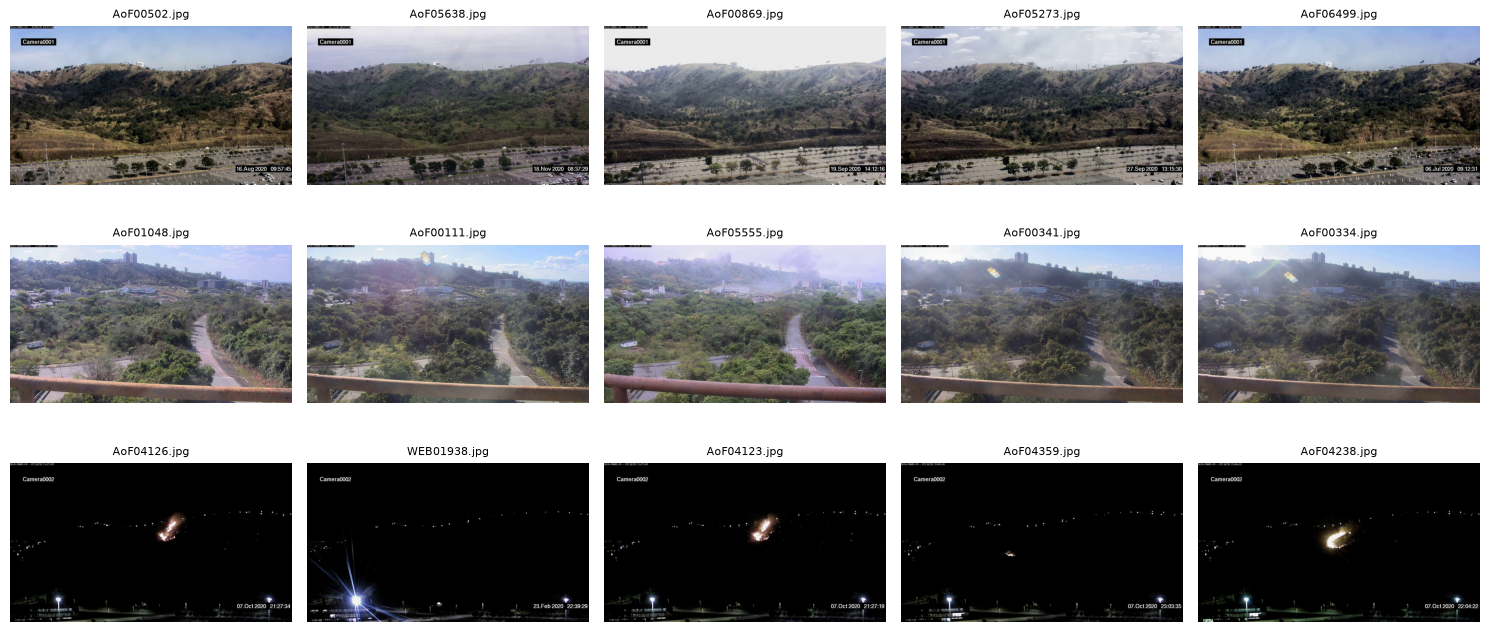

In [76]:
pool["group"] = near_duplicate_groups(hashes, MAX_DISTANCE)
pool["fold"] = assign_folds(pool["group"].to_numpy(), N_FOLDS, SEED)

# every group must sit in exactly one fold
assert (pool.groupby("group")["fold"].nunique() == 1).all() # a group split over two folds would leak near-duplicates between train and val

if folds_path.exists():
    # the saved folds were used by every training run, so the recomputed ones must match
    saved = pd.read_csv(folds_path).set_index("path")
    assert (saved.loc[pool["path"], "fold"].to_numpy() == pool["fold"].to_numpy()).all()
else:
    pool[["path", "split", "group", "fold"]].to_csv(folds_path, index=False)

# 5 images from each of the 3 biggest groups, one group per row
fig, axes = plt.subplots(3, 5, figsize=(15, 7))
for row, group in zip(axes, pool["group"].value_counts().index[:3]):
    for ax, path in zip(row, pool.loc[pool["group"] == group, "path"].sample(5, random_state=SEED)):
        ax.imshow(Image.open(DATASET_DIR / path))
        ax.set_title(Path(path).name, fontsize=8)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [77]:
pool["smoke_boxes"] = pool["boxes"].apply(lambda boxes: sum(box.category == 0 for box in boxes))
pool["fire_boxes"] = pool["boxes"].apply(lambda boxes: sum(box.category == 1 for box in boxes))
pool["source"] = pool["path"].str.extract(r"/([A-Za-z]+)\d+\.jpg$", expand=False)

# folds should have a similar size, class mix and sources
balance = pool.groupby("fold").agg(
    images=("path", "size"),
    groups=("group", "nunique"),
    no_boxes=("label", lambda label: (label == 0).mean()),
    smoke_boxes=("smoke_boxes", "sum"),
    fire_boxes=("fire_boxes", "sum"),
)
balance = balance.join(pd.crosstab(pool["fold"], pool["source"], normalize="index"))
balance.to_csv(CV_DIR / "fold_balance.csv")
balance.round(3)

,images,groups,no_boxes,smoke_boxes,fire_boxes,AoF,PublicDataset,WEB
fold,,,,,,,,
0,3445,1922,0.475,1901,2095,0.384,0.078,0.538
1,3444,1922,0.450,2002,2134,0.411,0.055,0.534
2,3444,1925,0.382,2074,3017,0.416,0.045,0.539
3,3444,1923,0.556,1611,2212,0.366,0.053,0.580
4,3444,1926,0.411,1955,2349,0.374,0.076,0.550


In [78]:
# how much the original splits leak
train_groups = set(pool.loc[pool["split"] == "train", "group"])
val = pool[pool["split"] == "val"]
print(f"{val['group'].isin(train_groups).sum()} of {len(val)} original val images share a group with a train image")

test = df[df["split"] == "test"]
test_hashes = np.stack([image_hash(DATASET_DIR / path) for path in test["path"]])
leaked = hash_distances(test_hashes, hashes).min(axis=1) <= MAX_DISTANCE # leaked if any train or val image is within MAX_DISTANCE bits
print(f"{leaked.sum()} of {len(test)} test images have a near-duplicate in train or val")

1459 of 3099 original val images share a group with a train image
2109 of 4306 test images have a near-duplicate in train or val


In [79]:
def load_runs(folder):
    runs = {}
    for run_dir in sorted(folder.glob("*/history.csv")):
        with open(run_dir.parent / "metadata.json") as f:
            runs[run_dir.parent.name] = (json.load(f), pd.read_csv(run_dir))
    return runs


def to_records(split_df, n_images):
    if n_images is not None:
        split_df = split_df.sample(n_images, random_state=SEED)
    return list(split_df[["path", "boxes"]].itertuples(index=False, name=None))


def train_fold(fold, params):
    # same augmentation as scripts/training/train.py
    train_dataset = ModelData(
        DATASET_DIR, to_records(pool[pool["fold"] != fold], CV_TRAIN_IMAGES), train_transform,
        flip_prob=0.5,
        zoom_prob=0.5, zoom_max=1.3
    )
    val_dataset = ModelData(DATASET_DIR, to_records(pool[pool["fold"] == fold], CV_VAL_IMAGES), eval_transform)

    loader_args = dict(
        batch_size=params["batch_size"],
        collate_fn=collate_fn,
        num_workers=params["num_workers"],
        pin_memory=params["pin_memory"],
    )
    train_loader = DataLoader(train_dataset, shuffle=True, **loader_args)
    val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

    # same random head and shuffle order every fold, but different train/val split
    torch.manual_seed(SEED)
    model = HybridModel().to(device)

    optimiser = AdamW(
        [
            # pretrained backbone gets smaller steps so the ImageNet features arent wiped out
            {"params": model.backbone.parameters(), "lr": params["learning_rate"] * 0.1},
            {"params": [p for name, p in model.named_parameters() if not name.startswith("backbone.")]},
        ],
        lr=params["learning_rate"],
        weight_decay=params["weight_decay"]
    )

    training_objs = TrainingObjects(
        model=model,
        optimizer=optimiser,
        criterion=YOLOLoss(model),
        scaler=torch.amp.GradScaler("cuda", enabled=device.type == "cuda"), # scales the loss up so small float16 gradients don't round to zero
        device=device,
        accumulation_steps=params["accumulation_steps"], # 4 batches of 8 add up before each step, same as a batch of 32
    )

    return Trainer(objs=training_objs).train_model(
        epochs=params["epochs"],
        train_loader=train_loader,
        val_loader=val_loader
    )

In [80]:
for name, changes in CV_RUNS.items():
    params = CV_PARAMS | changes
    run_dir = SAVED_MODELS / "cross_validation" / name
    done = [meta["notes"][0] for meta, _ in load_runs(run_dir).values() if meta["notes"][-1] == "completed"]
    missing = [fold for fold in range(N_FOLDS) if f"fold {fold} of {N_FOLDS}" not in done]

    if not missing:
        print(f"{name}: all {N_FOLDS} folds saved in models/cross_validation/{name}, using them")
        continue
    if not ALLOW_TRAINING:
        print(f"{name}: folds {missing} are not saved, set ALLOW_TRAINING = True to train them")
        continue

    save_runs_to(run_dir)
    for fold in missing:
        fold_note = f"fold {fold} of {N_FOLDS}"
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        results = train_fold(fold, params)

        model_info = {
            "timestamp": timestamp,
            "notes": [
                fold_note,
                f"train images {CV_TRAIN_IMAGES or 'all'}, val images {CV_VAL_IMAGES or 'all'}",
                "completed" if results.error is None else f"failed: {results.error!r}",
            ],
            "git_commit": git_commit,
            "parameters": params,
        }

        results.best_state = None # no model.pt
        Trainer.save_results(results, model_info, f"fold_{fold}")
    save_runs_to(SAVED_MODELS)

base: all 5 folds saved in models/cross_validation/base, using them
weight_decay_1e-3: all 5 folds saved in models/cross_validation/weight_decay_1e-3, using them


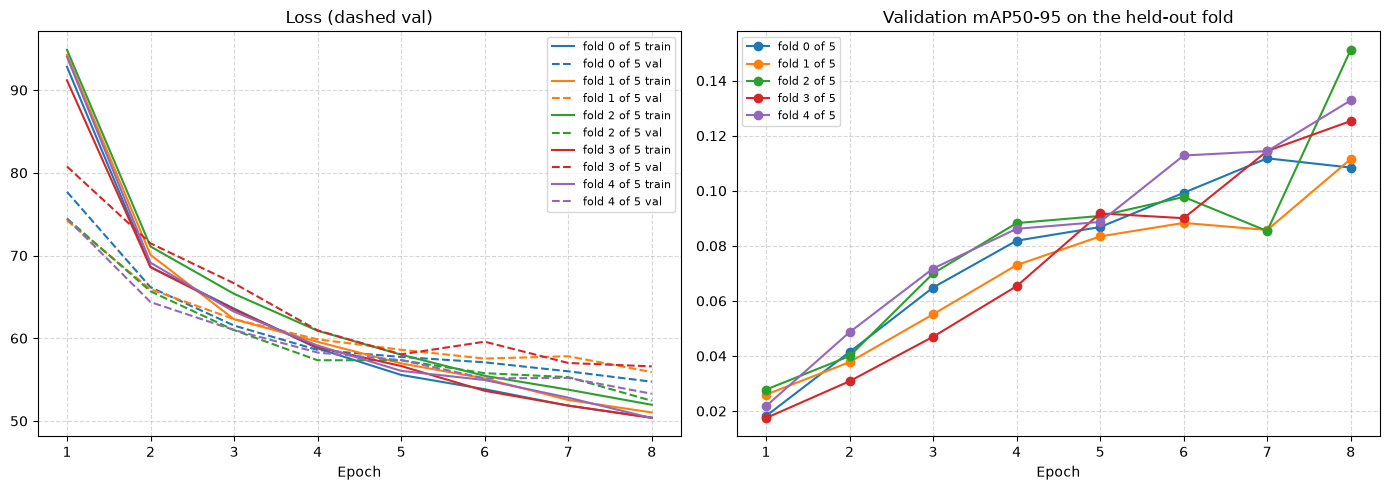

base


,run,epoch,map50,map50_95,recall50,mar_100
fold 0 of 5,fold_0,7.0,0.3167,0.1118,0.8677,0.4375
fold 1 of 5,fold_1,8.0,0.3168,0.1115,0.8269,0.3964
fold 2 of 5,fold_2,8.0,0.3739,0.1512,0.8742,0.4318
fold 3 of 5,fold_3,8.0,0.3326,0.1253,0.8514,0.4325
fold 4 of 5,fold_4,8.0,0.3413,0.1328,0.8828,0.4549
mean,NaN,NaN,0.3363,0.1265,0.8606,0.4306
std,NaN,NaN,0.0236,0.0165,0.0221,0.0213


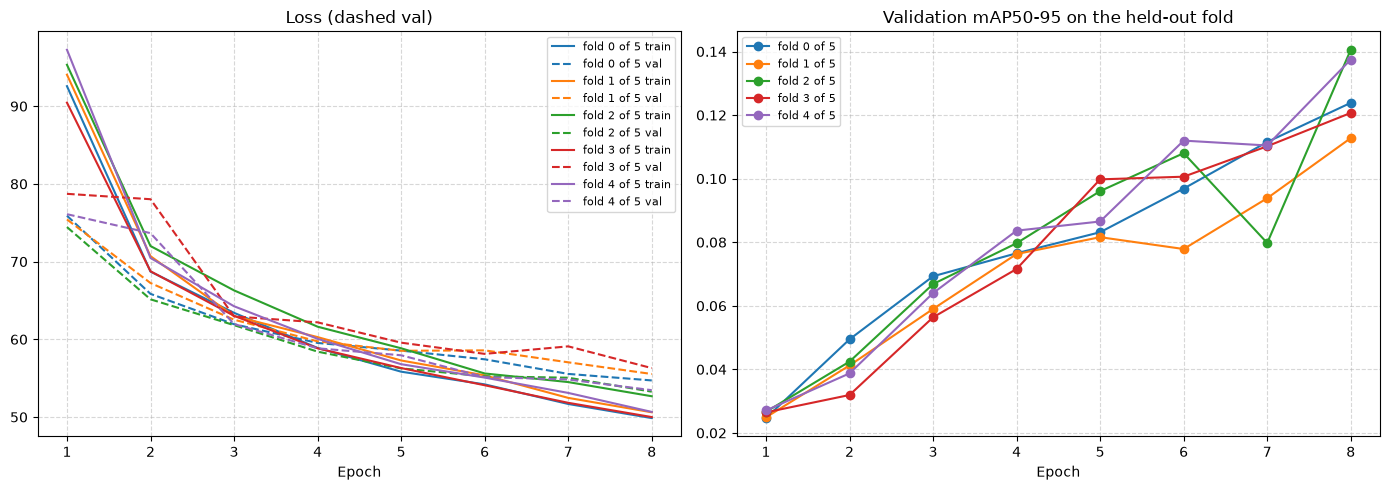

weight_decay_1e-3


,run,epoch,map50,map50_95,recall50,mar_100
fold 0 of 5,fold_0,8.0,0.3366,0.1239,0.8483,0.4347
fold 1 of 5,fold_1,8.0,0.3033,0.1128,0.8388,0.4087
fold 2 of 5,fold_2,8.0,0.3550,0.1406,0.8568,0.4269
fold 3 of 5,fold_3,8.0,0.3345,0.1207,0.8646,0.4264
fold 4 of 5,fold_4,8.0,0.3493,0.1375,0.8700,0.4417
mean,NaN,NaN,0.3357,0.1271,0.8557,0.4277
std,NaN,NaN,0.0200,0.0117,0.0125,0.0123


In [81]:
cv_tables = {}
for setting in CV_RUNS:
    runs = {name: run for name, run in load_runs(SAVED_MODELS / "cross_validation" / setting).items() if run[0]["notes"][-1] == "completed"}
    if not runs:
        print(f"{setting}: no completed folds yet, set ALLOW_TRAINING = True to train them")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    rows = []
    for name, (meta, history) in runs.items():
        fold = meta["notes"][0]
        line, = axes[0].plot(history["epoch"], history["train_loss"], label=f"{fold} train")
        axes[0].plot(history["epoch"], history["val_loss"], "--", color=line.get_color(), label=f"{fold} val")
        axes[1].plot(history["epoch"], history["map50_95"], marker="o", label=fold)

        best = history.loc[history["map50_95"].idxmax()]
        rows.append({"fold": fold, "run": name, **best[["epoch", "map50", "map50_95", "recall50", "mar_100"]]})

    axes[0].set_title("Loss (dashed val)")
    axes[1].set_title("Validation mAP50-95 on the held-out fold")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(linestyle="--", alpha=0.5)
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(CV_PLOT_DIR / f"{setting}_folds.svg")
    plt.show()

    # best epoch per fold, then mean and std
    table = pd.DataFrame(rows).set_index("fold")
    metrics = table[["map50", "map50_95", "recall50", "mar_100"]]
    table = pd.concat([table, metrics.agg(["mean", "std"])])
    table.to_csv(CV_DIR / f"{setting}_folds.csv")
    print(setting)
    display(table.round(4))
    cv_tables[setting] = table

In [82]:
# paired: both settings are scored on the same five held-out folds
assert len(cv_tables) == 2, "both cross-validation runs need all their folds"
per_fold = pd.concat({setting: table["map50_95"].iloc[:N_FOLDS] for setting, table in cv_tables.items()}, axis=1)
per_fold["difference"] = per_fold["weight_decay_1e-3"] - per_fold["base"]
test_result = stats.ttest_rel(per_fold["weight_decay_1e-3"], per_fold["base"]) # how likely the fold-by-fold difference is just noise

display(per_fold.round(4))
print(f"mean difference {per_fold['difference'].mean():+.4f}, paired t-test p = {test_result.pvalue:.2f}")

,base,weight_decay_1e-3,difference
fold 0 of 5,0.1118,0.1239,0.0121
fold 1 of 5,0.1115,0.1128,0.0012
fold 2 of 5,0.1512,0.1406,-0.0107
fold 3 of 5,0.1253,0.1207,-0.0046
fold 4 of 5,0.1328,0.1375,0.0047


mean difference +0.0005, paired t-test p = 0.90


## 4. Results and Evaluation

### Final model training and test evaluation

*Code: Ciaran Whelan. Report: Results and Evaluation.*

`scripts/training/train.py`

Changed: only trains if `ALLOW_TRAINING = True` and `FINAL_MODEL` isn't saved (was `if __name__ == "__main__":`). Training takes about 3 hours, so the saved run is shown below.

In [83]:
"""
    python -m scripts.training.train
"""
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW

import json
import pandas as pd
from datetime import datetime

import subprocess
import gc

if ALLOW_TRAINING and not (SAVED_MODELS / FINAL_MODEL / "model.pt").exists():
    MODEL_DIR.mkdir(parents=True, exist_ok=True)

    df = pd.read_csv(CSV_DIR / "data/metadata.csv")
    df["boxes"] = df["boxes"].apply(lambda value: parse_boxes(json.loads(value)))

    device = get_device()
    git_commit = subprocess.check_output( ["git", "rev-parse", "HEAD"], text=True ).strip()
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    NOTES = [
        "Test"
    ]

    PARAMS: ModelParameters = {
        "seed": 42,
        "num_workers": 8,
        "pin_memory": device.type == "cuda",
        
        "batch_size": 8,
        "epochs": 50,
        "accumulation_steps": 4,

        "learning_rate": 1e-3,
        "weight_decay": 1e-4,

        "model_name": "model.pt",
    }

    MODEL_INFO: ModelInfo = {
        "timestamp": timestamp,
        "notes" : NOTES,
        "git_commit" : git_commit,
        "parameters": PARAMS,
    }

    train_data = list(
        df.loc[df["split"] == "train", ["path", "boxes"]]
        .itertuples(index=False, name=None)
    )

    val_data = list(
        df.loc[df["split"] == "val", ["path", "boxes"]]
        .itertuples(index=False, name=None)
    )

    test_data = list(
        df.loc[df["split"] == "test", ["path", "boxes"]]
        .itertuples(index=False, name=None)
    )

    train_dataset = ModelData(
        DATASET_DIR, train_data, train_transform, 
        flip_prob=0.5,
        zoom_prob=0.5, zoom_max=1.3
        )
    
    val_dataset = ModelData(DATASET_DIR, val_data, eval_transform)
    test_dataset = ModelData(DATASET_DIR, test_data, eval_transform)

    train_loader = DataLoader(
        train_dataset,
        batch_size=PARAMS["batch_size"],
        shuffle=True,
        collate_fn=collate_fn,
        num_workers=PARAMS["num_workers"],
        pin_memory=PARAMS["pin_memory"]
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=PARAMS["batch_size"],
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=PARAMS["num_workers"],
        pin_memory=PARAMS["pin_memory"]
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=PARAMS["batch_size"],
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=PARAMS["num_workers"],
        pin_memory=PARAMS["pin_memory"]
    )

    model = HybridModel().to(device)

    optimiser = AdamW(
        [
            #pretrained backbone: smaller steps so the ImageNet features aren't wiped out
            {"params": model.backbone.parameters(), "lr": PARAMS["learning_rate"] * 0.1},
            # adapter, neck and head start from random init so use the full rate
            {"params": [p for name, p in model.named_parameters() if not name.startswith("backbone.")]},
        ],
        lr=PARAMS["learning_rate"], 
        weight_decay=PARAMS["weight_decay"]
    )

    criterion = YOLOLoss(model) 

    scaler = torch.amp.GradScaler("cuda")

    training_objs = TrainingObjects(
        model=model,
        optimizer=optimiser,
        criterion=criterion,
        scaler=scaler,
        device=device,
        accumulation_steps=PARAMS["accumulation_steps"],
    )

    trainer = Trainer(objs=training_objs)

    results = trainer.train_model(
        epochs=PARAMS["epochs"],
        train_loader=train_loader,
        val_loader=val_loader
    )
    if results.error is not None:
        raise results.error
    
    try:        
        if results.best_state is not None:
            training_objs.model.load_state_dict(results.best_state)
            test_history = trainer.evaluate(test_loader)
            print_evaluation(test_history)

            trainer.save_results(
                results,
                model_info=MODEL_INFO,
                timestamp=timestamp
            )
    finally:
        del trainer
        gc.collect()

        if device.type == "cuda":
            torch.cuda.empty_cache()

In [84]:
# the saved output of train.py for the final model
with open(SAVED_MODELS / FINAL_MODEL / "metadata.json") as f:
    print(json.dumps(json.load(f), indent=4))

pd.read_csv(SAVED_MODELS / FINAL_MODEL / "history.csv").round(4)

{
    "timestamp": "20261029_154330",
    "notes": [
        "Model with random zoom-ins and flips"
    ],
    "git_commit": "006864f1fc4f5a078ed18a2e2e6f2fd8c526af6e",
    "parameters": {
        "seed": 42,
        "num_workers": 8,
        "pin_memory": true,
        "batch_size": 8,
        "epochs": 50,
        "accumulation_steps": 4,
        "learning_rate": 0.001,
        "weight_decay": 0.0001,
        "model_name": "model.pt"
    }
}


,epoch,train_loss,val_loss,map50,map50_95,map_small,map_medium,map_large,mar_100,mar_small,mar_medium,mar_large,recall50,recall50_small,recall50_medium,recall50_large,recall75,recall75_small,recall75_medium,recall75_large
0,1,71.2557,57.1602,0.2084,0.0720,0.0379,0.0974,0.0757,0.4184,0.2970,0.4379,0.4603,0.8606,0.6747,0.8855,0.9252,0.3256,0.2021,0.3538,0.3666
1,2,54.9768,51.2453,0.3531,0.1394,0.0793,0.1874,0.1296,0.4774,0.3228,0.4893,0.5161,0.8940,0.7655,0.9054,0.9286,0.4542,0.2013,0.4656,0.5204
2,3,50.3361,48.4574,0.4644,0.1905,0.1153,0.2339,0.1793,0.4863,0.2710,0.5233,0.5463,0.8977,0.6885,0.9427,0.9579,0.4749,0.1579,0.5063,0.5783
3,4,47.3724,44.0848,0.5526,0.2627,0.1558,0.2818,0.2841,0.5338,0.3958,0.5575,0.5630,0.9244,0.8238,0.9519,0.9476,0.5638,0.3187,0.5967,0.6194
4,5,44.4913,42.7296,0.6087,0.2985,0.1658,0.3164,0.3243,0.5464,0.3952,0.5682,0.5755,0.9297,0.8165,0.9485,0.9567,0.5922,0.3447,0.6241,0.6413
5,6,42.5953,42.5969,0.6080,0.2910,0.1908,0.3177,0.3139,0.5431,0.3986,0.5696,0.5827,0.9317,0.8243,0.9580,0.9639,0.5821,0.3357,0.6212,0.6440
6,7,40.5505,41.1430,0.6397,0.3151,0.1725,0.3162,0.3642,0.5328,0.3366,0.5627,0.5983,0.9118,0.7589,0.9582,0.9531,0.5539,0.2393,0.5902,0.6730
7,8,39.2900,40.3324,0.6397,0.3219,0.1832,0.3429,0.3383,0.5550,0.3632,0.5648,0.6146,0.9236,0.7698,0.9476,0.9663,0.5900,0.2883,0.5909,0.7066
8,9,38.1195,40.4900,0.6560,0.3284,0.1914,0.3528,0.3675,0.5476,0.3971,0.5758,0.5833,0.9207,0.8189,0.9519,0.9471,0.5879,0.3368,0.6346,0.6569
9,10,37.5500,39.1151,0.6736,0.3456,0.2020,0.3505,0.3959,0.5508,0.3825,0.5584,0.6034,0.9229,0.7988,0.9480,0.9507,0.5827,0.3089,0.6104,0.6692


`scripts/training/evaluate.py`

Changed: evaluates `FINAL_MODEL` instead of run `20261028_114248`.

In [85]:
"""
    python -m scripts.training.train
"""
import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW

import json
import pandas as pd
from datetime import datetime

import subprocess
import gc

if __name__ == "__main__":
    model_dir = MODEL_DIR / FINAL_MODEL
    print(model_dir)

    df = pd.read_csv(CSV_DIR / "data/metadata.csv")
    df["boxes"] = df["boxes"].apply(lambda value: parse_boxes(json.loads(value)))

    device = get_device()
    git_commit = subprocess.check_output( ["git", "rev-parse", "HEAD"], text=True ).strip()
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    with open(model_dir / "metadata.json", "r") as f:
        meta = json.load(f)

    PARAMS = meta["parameters"]

    test_data = list(
        df.loc[df["split"] == "test", ["path", "boxes"]]
        .itertuples(index=False, name=None)
    )
    test_dataset = ModelData(DATASET_DIR, test_data, eval_transform)

    test_loader = DataLoader(
        test_dataset,
        batch_size=PARAMS["batch_size"],
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=PARAMS["num_workers"],
        pin_memory=PARAMS["pin_memory"]
    )

    model = HybridModel().to(device)
    state_dict = torch.load(
        model_dir / "model.pt",
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state_dict)

    criterion = YOLOLoss(model) 

    training_objs = TrainingObjects(
        model=model,
        optimizer=torch.optim.AdamW(model.parameters()),
        criterion=criterion,
        scaler=torch.GradScaler(),
        device=device,
        accumulation_steps=0,
    )

    trainer = Trainer(objs=training_objs)

    try:        
        test_history = trainer.evaluate(test_loader)
        print_evaluation(test_history)
    finally:
        del trainer
        gc.collect()

        if device.type == "cuda":
            torch.cuda.empty_cache()

c:\Users\26roc\Projects\CS4287-JJ-Project\results\models\20261029_154330
2.14.1+cu130
13.0
True
1
Device: cuda

                        MODEL EVALUATION

Overall mAP50:     0.7414
Overall mAP50-95:  0.4070

Detection performance by object size
------------------------------------------------------------------------
Size                  mAP          mAR      Recall@50      Recall@75
------------------------------------------------------------------------
Overall            0.4070       0.5492         0.9042         0.5614
Small              0.2708       0.4104         0.8272         0.3429
Medium             0.4044       0.5480         0.9205         0.5670
Large              0.4727       0.6064         0.9248         0.6530

Per-class mAP50-95
------------------------------------------------------------------------
Smoke        0.4689
Fire         0.3451


### Test scores with and without near-duplicates

*Code: Hersh Singh. Report: Near-Duplicates in the Test Split.*

Scores the final model on the test split with and without the near-duplicates found in section 3.

In [86]:
weights = SAVED_MODELS / FINAL_MODEL / "model.pt"
assert weights.exists(), f"{weights} is missing, train the final model in the section above first"

model = HybridModel().to(device)
model.load_state_dict(torch.load(weights, map_location=device, weights_only=True)) # reuse the trained weights instead of training the final model again
model.eval()

test_df = test.reset_index(drop=True)
test_df["near_duplicate"] = leaked

loader_args = dict(batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
test_loader = DataLoader(ModelData(DATASET_DIR, to_records(test_df, None), eval_transform), shuffle=False, **loader_args)

# Trainer.evaluate only returns the totals, so the detections are kept here per image
predictions, ground_truth = [], []
with torch.no_grad():
    for images, targets in test_loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            outputs = model(images.to(device))
        for det in non_max_suppression(outputs, conf_thres=0.001, iou_thres=0.7, max_det=300): # drop overlapping duplicate boxes, same thresholds Ultralytics validates with
            predictions.append({"boxes": det[:, :4].float().cpu(), "scores": det[:, 4].float().cpu(), "labels": det[:, 5].long().cpu()})
        ground_truth += Trainer._ground_truth(targets, len(images), images.shape[-2:])

In [87]:
def score(mask):
    metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True, max_detection_thresholds=[1, 10, 100])
    metric.update([p for p, keep in zip(predictions, mask) if keep], [g for g, keep in zip(ground_truth, mask) if keep]) # only the images in this subset are scored
    result = metric.compute()
    return {
        "images": int(np.sum(mask)),
        "mAP50": result["map_50"].item(),
        "mAP50-95": result["map"].item(),
        "smoke mAP50-95": result["map_per_class"][0].item(),
        "fire mAP50-95": result["map_per_class"][1].item(),
        "mAR100": result["mar_100"].item(),
    }


OUT_CSV = CSV_DIR / "evaluation"
OUT_CSV.mkdir(parents=True, exist_ok=True)

near = test_df["near_duplicate"].to_numpy()
subsets = pd.DataFrame({
    "all test images": score(np.ones(len(test_df), dtype=bool)),
    "no near-duplicate in train/val": score(~near),
    "near-duplicate in train/val": score(near),
}).T
subsets.to_csv(OUT_CSV / "test_near_duplicates.csv")
display(subsets.round(4))

,images,mAP50,mAP50-95,smoke mAP50-95,fire mAP50-95,mAR100
all test images,4306.0,0.7414,0.4070,0.4689,0.3451,0.5492
no near-duplicate in train/val,2197.0,0.6985,0.3778,0.4632,0.2924,0.5335
near-duplicate in train/val,2109.0,0.8594,0.5044,0.4910,0.5177,0.6042


## 5. Independent Experiments: Hyperparameter Tuning

*Code: Hersh Singh. Report: Hyperparameter Tuning.*

Each experiment changes one setting from `BASE` and validates on fold 0.

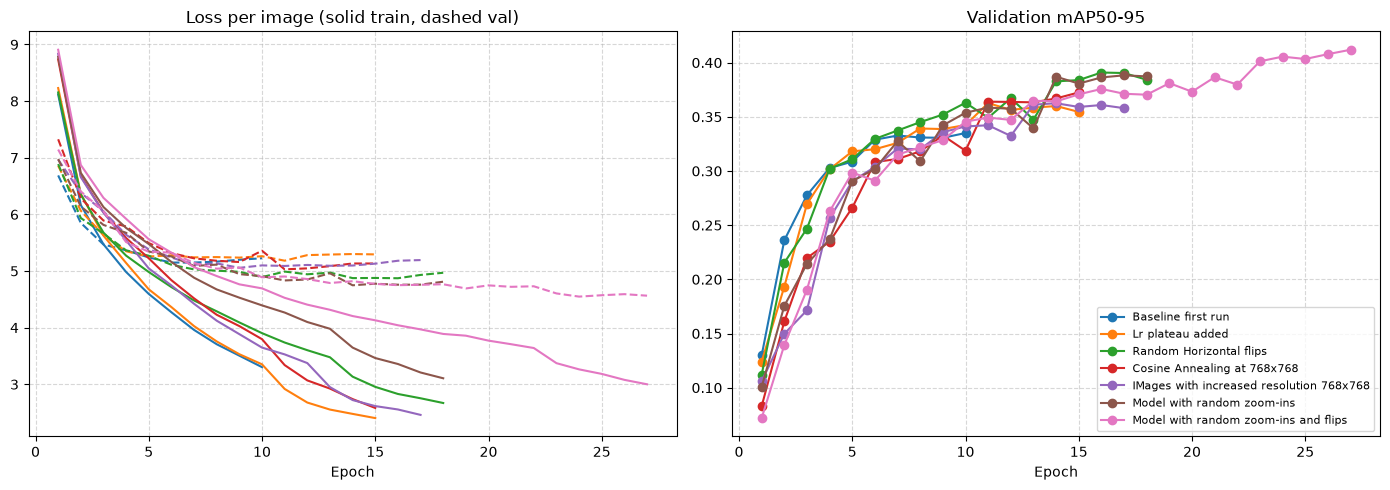

,run,experiment,notes,learning_rate,weight_decay,epochs,best_epoch,best_map50,best_map50_95,best_recall50,best_mar_100
0,20261028_003332,Baseline first run,Baseline first run,0.001,0.0001,10,10,0.6566,0.3351,NaN,NaN
1,20261028_091721,Lr plateau added,Lr plateau added,0.001,0.0001,15,11,0.6876,0.3626,NaN,NaN
2,20261028_114248,Random Horizontal flips,Random Horizontal flips,0.001,0.0001,18,16,0.7211,0.3909,NaN,NaN
3,20261028_231315,Cosine Annealing at 768x768,Cosine Annealing at 768x768,0.001,0.0001,15,15,0.6991,0.3725,0.8479,0.5017
4,20261029_094103,IMages with increased resolution 768x768,IMages with increased resolution 768x768,0.001,0.0001,17,14,0.6854,0.3625,0.8480,0.5015
5,20261029_125508,Model with random zoom-ins,Model with random zoom-ins,0.001,0.0001,18,17,0.7210,0.3883,0.9044,0.5428
6,20261029_154330,Model with random zoom-ins and flips,Model with random zoom-ins and flips,0.001,0.0001,27,27,0.7329,0.4119,0.8940,0.5522


In [88]:
# one folder per experiment, named by what it changes from BASE
TUNING_RUN_DIR = SAVED_MODELS / "hyperparameter_tuning"

TUNING_DIR = CSV_DIR / "hyperparameter_tuning"
TUNING_PLOT_DIR = PLOT_DIR / "hyperparameter_tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)
TUNING_PLOT_DIR.mkdir(parents=True, exist_ok=True)


def load_runs(folder):
    runs = {}
    for run_dir in sorted(folder.iterdir()):
        if not (run_dir / "history.csv").exists():
            continue

        with open(run_dir / "metadata.json") as f:
            meta = json.load(f)

        # older runs prefix the metrics with val_
        history = pd.read_csv(run_dir / "history.csv")
        history = history.rename(columns=lambda c: c if c == "val_loss" else c.removeprefix("val_"))
        runs[run_dir.name] = (meta, history)
    return runs


def short_label(note):
    # name a run by what it changes from BASE, so the reference run reads "base"
    parts = note.split(", val fold")[0].split(", ")
    base = [
        f"learning rate {BASE['learning_rate']:g}", f"weight decay {BASE['weight_decay']:g}",
        f"backbone lr x{BASE['backbone_lr_scale']:g}", f"augmentation {'on' if BASE['augmentation'] else 'off'}",
    ]
    if len(parts) != len(base):
        return note # older runs have free text notes
    return ", ".join(p for p, b in zip(parts, base) if p != b) or "base"


def plot_runs(runs, path):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for name, (meta, history) in runs.items():
        batch_size = meta["parameters"]["batch_size"]
        label = short_label(meta["notes"][0])
        line, = axes[0].plot(history["epoch"], history["train_loss"] / batch_size)
        axes[0].plot(history["epoch"], history["val_loss"] / batch_size, "--", color=line.get_color())
        axes[1].plot(history["epoch"], history["map50_95"], marker="o", color=line.get_color(), label=label)

    axes[0].set_title("Loss per image (solid train, dashed val)")
    axes[1].set_title("Validation mAP50-95")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(linestyle="--", alpha=0.5)
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(path)
    plt.show()


def summarise(runs):
    rows = []
    for name, (meta, history) in runs.items():
        best = history.loc[history["map50_95"].idxmax()]
        rows.append({
            "run": name,
            "experiment": meta["notes"][0],
            "notes": ", ".join(meta["notes"]),
            "learning_rate": meta["parameters"]["learning_rate"],
            "weight_decay": meta["parameters"]["weight_decay"],
            "epochs": len(history),
            "best_epoch": int(best["epoch"]),
            "best_map50": best["map50"],
            "best_map50_95": best["map50_95"],
            "best_recall50": best.get("recall50"),
            "best_mar_100": best.get("mar_100"),
        })
    return pd.DataFrame(rows)


# the full-length runs in results/models, for comparison
historical = load_runs(SAVED_MODELS)
plot_runs(historical, TUNING_PLOT_DIR / "full_length_runs.svg")

historical_table = summarise(historical)
historical_table.to_csv(TUNING_DIR / "full_length_runs.csv", index=False)
historical_table.round(4)

In [89]:
# in the saved fold order, so the samples below are the images the saved runs used
tuning_df = pd.read_csv(CSV_DIR / "data/folds.csv")[["path", "fold"]].merge(df, on="path")

train_df = tuning_df[tuning_df["fold"] != VAL_FOLD]
val_df = tuning_df[tuning_df["fold"] == VAL_FOLD]
print(f"{len(train_df)} train and {len(val_df)} val images to sample from")

train_data = list(train_df.sample(TRAIN_IMAGES, random_state=SEED)[["path", "boxes"]].itertuples(index=False, name=None))
val_data = list(val_df.sample(VAL_IMAGES, random_state=SEED)[["path", "boxes"]].itertuples(index=False, name=None))

train_dataset = ModelData(
    DATASET_DIR, train_data, train_transform,
    flip_prob=0.5,
    zoom_prob=0.5, zoom_max=1.3
)
val_dataset = ModelData(DATASET_DIR, val_data, eval_transform)

# seeded in train_experiment so every run sees the same image order
generator = torch.Generator()
loader_args = dict(batch_size=BATCH_SIZE, collate_fn=collate_fn, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
train_loader = DataLoader(train_dataset, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)

13776 train and 3445 val images to sample from


In [90]:
torch.manual_seed(SEED)
initial_state = HybridModel().state_dict()


def describe(settings):
    return (
        f"learning rate {settings['learning_rate']:g}, weight decay {settings['weight_decay']:g}, "
        f"backbone lr x{settings['backbone_lr_scale']:g}, augmentation {'on' if settings['augmentation'] else 'off'}"
    )


def folder_name(settings):
    # readable run folder, named by what the experiment changes from BASE
    fmt = lambda value: f"{value:.0e}".replace("e-0", "e-")
    changed = []
    if settings["learning_rate"] != BASE["learning_rate"]:
        changed.append(f"lr_{fmt(settings['learning_rate'])}")
    if settings["weight_decay"] != BASE["weight_decay"]:
        changed.append(f"weight_decay_{fmt(settings['weight_decay'])}")
    if settings["backbone_lr_scale"] != BASE["backbone_lr_scale"]:
        changed.append(f"backbone_lr_x{settings['backbone_lr_scale']:g}")
    if settings["augmentation"] != BASE["augmentation"]:
        changed.append(f"augmentation_{'on' if settings['augmentation'] else 'off'}")
    return "_".join(changed) or "base"


def train_experiment(settings):
    model = HybridModel().to(device)
    model.load_state_dict(initial_state)

    optimiser = AdamW(
        [
            # pretrained backbone gets smaller steps so the ImageNet features arent wiped out
            {"params": model.backbone.parameters(), "lr": settings["learning_rate"] * settings["backbone_lr_scale"]},
            {"params": [p for name, p in model.named_parameters() if not name.startswith("backbone.")]},
        ],
        lr=settings["learning_rate"],
        weight_decay=settings["weight_decay"]
    )

    training_objs = TrainingObjects(
        model=model,
        optimizer=optimiser,
        criterion=YOLOLoss(model),
        scaler=torch.amp.GradScaler("cuda", enabled=device.type == "cuda"),
        device=device,
        accumulation_steps=ACCUMULATION_STEPS,
    )

    # workers restart each epoch, so they pick these up
    train_dataset.flip_prob = 0.5 if settings["augmentation"] else 0.0
    train_dataset.zoom_prob = 0.5 if settings["augmentation"] else 0.0

    torch.manual_seed(SEED)
    generator.manual_seed(SEED) # same shuffle order for every experiment, so only the setting changes

    return Trainer(objs=training_objs).train_model(epochs=EPOCHS, train_loader=train_loader, val_loader=val_loader)

In [91]:
def experiment_note(settings):
    return f"{describe(settings)}, val fold {VAL_FOLD}, train images {TRAIN_IMAGES}, val images {VAL_IMAGES}"


done = [meta["notes"][0] for meta, _ in load_runs(TUNING_RUN_DIR).values() if "completed" in meta["notes"]] if TUNING_RUN_DIR.exists() else []
missing = [changes for changes in EXPERIMENTS if experiment_note(BASE | changes) not in done]

if not missing:
    print(f"all {len(EXPERIMENTS)} experiments saved in models/hyperparameter_tuning, using them")
elif not ALLOW_TRAINING:
    print(f"{len(missing)} experiments are not saved, set ALLOW_TRAINING = True to train them")
else:
    save_runs_to(TUNING_RUN_DIR)
    for changes in missing:
        settings = BASE | changes
        experiment = experiment_note(settings)

        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

        print(describe(settings))
        results = train_experiment(settings)

        if results.error is None:
            best = results.history.eval[results.best_epoch - 1]
            print_evaluation(best)
            notes = [experiment, "completed", f"[smoke, fire] mAP50-95 {np.round(best.evaluation.map_per_class, 4).tolist()}"]
        else:
            notes = [experiment, f"failed: {results.error!r}"]

        model_info = {
            "timestamp": timestamp,
            "notes": notes,
            "git_commit": git_commit,
            "parameters": {
                "seed": SEED, "num_workers": NUM_WORKERS, "pin_memory": device.type == "cuda",
                "batch_size": BATCH_SIZE, "epochs": EPOCHS, "accumulation_steps": ACCUMULATION_STEPS,
                "learning_rate": settings["learning_rate"], "weight_decay": settings["weight_decay"],
                "model_name": "not saved",
            },
        }

        results.best_state = None # no model.pt
        Trainer.save_results(results, model_info, folder_name(settings))
    save_runs_to(SAVED_MODELS)

all 9 experiments saved in models/hyperparameter_tuning, using them


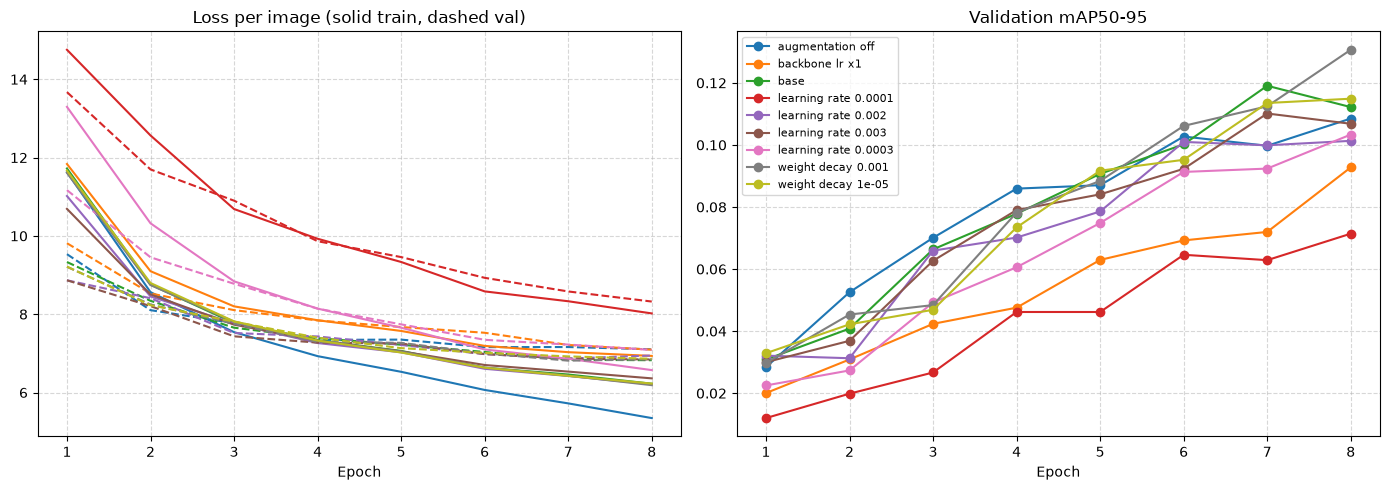

,run,experiment,notes,learning_rate,weight_decay,epochs,best_epoch,best_map50,best_map50_95,best_recall50,best_mar_100
7,weight_decay_1e-3,"learning rate 0.001, weight decay 0.001, backb...","learning rate 0.001, weight decay 0.001, backb...",0.0010,0.0010,8,8,0.3557,0.1307,0.8652,0.4374
2,base,"learning rate 0.001, weight decay 0.0001, back...","learning rate 0.001, weight decay 0.0001, back...",0.0010,0.0001,8,7,0.3342,0.1191,0.8693,0.4334
8,weight_decay_1e-5,"learning rate 0.001, weight decay 1e-05, backb...","learning rate 0.001, weight decay 1e-05, backb...",0.0010,0.0000,8,8,0.3349,0.1149,0.8590,0.4394
5,lr_3e-3,"learning rate 0.003, weight decay 0.0001, back...","learning rate 0.003, weight decay 0.0001, back...",0.0030,0.0001,8,7,0.3002,0.1101,0.8717,0.4372
0,augmentation_off,"learning rate 0.001, weight decay 0.0001, back...","learning rate 0.001, weight decay 0.0001, back...",0.0010,0.0001,8,8,0.3047,0.1085,0.8259,0.4044
6,lr_3e-4,"learning rate 0.0003, weight decay 0.0001, bac...","learning rate 0.0003, weight decay 0.0001, bac...",0.0003,0.0001,8,8,0.2826,0.1033,0.8535,0.4348
4,lr_2e-3,"learning rate 0.002, weight decay 0.0001, back...","learning rate 0.002, weight decay 0.0001, back...",0.0020,0.0001,8,8,0.2969,0.1013,0.8426,0.4275
1,backbone_lr_x1,"learning rate 0.001, weight decay 0.0001, back...","learning rate 0.001, weight decay 0.0001, back...",0.0010,0.0001,8,8,0.2646,0.0928,0.8433,0.4218
3,lr_1e-4,"learning rate 0.0001, weight decay 0.0001, bac...","learning rate 0.0001, weight decay 0.0001, bac...",0.0001,0.0001,8,8,0.2156,0.0714,0.8249,0.3985


In [92]:
if TUNING_RUN_DIR.exists():
    candidates = load_runs(TUNING_RUN_DIR)
    plot_runs(candidates, TUNING_PLOT_DIR / "experiments.svg")

    table = summarise(candidates).sort_values("best_map50_95", ascending=False)
    table.to_csv(TUNING_DIR / "experiments.csv", index=False)
    display(table.round(4))
else:
    print("No runs yet, set ALLOW_TRAINING = True to train them")

In [93]:
if TUNING_RUN_DIR.exists():
    completed = table[table["notes"].str.contains("completed")]
    best = completed["best_map50_95"].iloc[0] if len(completed) else 0.0
    runner_up = completed["best_map50_95"].iloc[1] if len(completed) > 1 else 0.0

    # one seed and a sample of val images, gaps under 0.01 count as noise
    if best < 0.01:
        print("No winner: every experiment is still near zero mAP, train for longer")
    elif best - runner_up < 0.01:
        print(f"Tie: {completed['experiment'].iloc[0]} is ahead by only {best - runner_up:.4f}")
    else:
        print(f"Best: {completed['experiment'].iloc[0]} (mAP50-95 {best:.4f}, ahead by {best - runner_up:.4f})")

Best: learning rate 0.001, weight decay 0.001, backbone lr x0.1, augmentation on, val fold 0, train images 3000, val images 1000 (mAP50-95 0.1307, ahead by 0.0116)
